<a href="https://colab.research.google.com/github/fhs8426004/i2wi-learning-fhs8426004/blob/main/unit17_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 深層学習（古典的）（ユニット17）

**深層学習は、機械学習のひとつです。** 第6・7回の手順（分ける → 訓練する → 検証で選ぶ → テストは1回）は、そのまま使います。変わるのは、**モデルが「層を重ねた関数」になり、重みを「勾配」で少しずつ直していく**ことです。この回では、**一番小さいネットワークを自分の手で組み、学習の中身（勾配降下・誤差逆伝播）を数値で確かめ**、そのあと**画像のモデルが何を見ているか（GradCAM）**を調べます。

| 節 | 問い | 動かすもの |
|---|---|---|
| 1. 歴史 | どこから来たか | （表だけ） |
| 2. できること・ワークフロー | 第6・7回と、何が同じで何が違うか | （表だけ） |
| 3. モデルの移り変わり | DNN から LLM・VLM・エージェントまで | （表だけ） |
| 4. 一番小さいネットワーク | 入力・組み立て・出力 | PyTorch、numpy での手計算 |
| 5. 学習の仕組み | 勾配降下・誤差逆伝播 | 手書きの勾配と自動微分の一致、学習率 |
| 6. 訓練を検証する | 誤差・精度の曲線、過学習、早期終了、テスト | 訓練曲線、10回の学習 |
| 7. 活性化関数と損失関数 | 部品の選び方。最後の「参考」は、モデルごとの損失の違い（解説のみ） | 活性化関数と微分、出力の関数と損失 |
| 8. 説明可能性 GradCAM | モデルは、画像のどこを見て答えたか | PneumoniaMNIST、GradCAM |
| 9. このあとに | 18・19 回へ | （表だけ） |

**使うデータ**: 4〜7 節は Breast Cancer Wisconsin (Diagnostic)（第4・6・7回と同じ。scikit-learn に同梱）。8 節は **PneumoniaMNIST**（小児の胸部 X 線 4,708 枚＋検証・テスト。**実行時にダウンロード**、約 20 MB）。

**図の文字は英語**にしています（Colab の既定フォントに日本語が無く、文字化けするため）。

**数値は、実行する環境で少し変わります。** 乱数の種は固定していますが、PyTorch は CPU の種類やバージョンで、小数の下の方が変わることがあります。**結論（どちらが大きい、どう動く）は変わりません**。

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix

# 図の色を先に決めておく（BLUE=主役、ORANGE=強調・注意、INK=文字と基準線、MUTED=補助）。以降の図で同じ意味に使う
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
# 図の見た目をまとめて設定（解像度、上と右の枠線を消す、薄い罫線）。内容には関係しない
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

# データを読む。悪性 = 1、良性 = 0 にそろえる（scikit-learn の元の値は逆。第6・7回と同じ）
raw = load_breast_cancer(as_frame=True)
X = raw.data.values
y = (raw.target.values == 0).astype(int)

# 分け方は第6回と同じ。まずテスト用を 2 割（乱数の種 0 と 0.2 は人が決めた値）
Xdev, Xte, ydev, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
# 残りを、訓練用 75%・検証用 25% に分ける（開発用の 4 分の 1 が検証用。人が決めた値）
Xtr, Xva, ytr, yva = train_test_split(Xdev, ydev, test_size=0.25, stratify=ydev, random_state=0)
print("train", Xtr.shape, "validation", Xva.shape, "test", Xte.shape)

# 標準化は、訓練用だけで平均と標準偏差を求める（検証・テストの情報を使わない。第6回の漏れの教訓）。ネットワークは、特徴量の大きさがそろっていないと学習が遅い
scaler = StandardScaler().fit(Xtr)
def to_t(a): return torch.tensor(scaler.transform(a), dtype=torch.float32)       # 標準化して、PyTorch のテンソル（数の配列）にする
def to_y(a): return torch.tensor(a, dtype=torch.float32)                          # ラベルも、損失の計算用に小数にする
Ttr, Tva, Tte = to_t(Xtr), to_t(Xva), to_t(Xte)
ttr, tva, tte = to_y(ytr), to_y(yva), to_y(yte)

train (341, 30) validation (114, 30) test (114, 30)


## 1. 歴史 — 深層学習は、どこから来たか

出典は、論文の書誌を **Crossref（DOI の公式データベース）で照合**したものです（2026-10-14）。arXiv の論文は、arXiv のページで確認しました。**年は、その論文が発表された年**で、「その考えが生まれた年」ではありません。

| 年 | 出来事 | 出典 |
|---|---|---|
| 1943 | 神経細胞を、論理で書けるスイッチとして数式にした（形式ニューロン） | McCulloch & Pitts. Bull Math Biophys 5:115-133 |
| 1958 | パーセプトロン。重みを、間違いから自動で直す | Rosenblatt. Psychol Rev 65:386-408 |
| 1969 | 単層のパーセプトロンの限界を、数学で示した本 | Minsky & Papert. 『Perceptrons』（MIT Press。初版。Crossref では 1969 年の書評で確認） |
| 1986 | 誤差逆伝播法。多層のネットワークの重みを、効率よく直せる | Rumelhart, Hinton, Williams. Nature 323:533-536 |
| 1989 | 層が十分に大きければ、どんな連続な関数も近似できる（普遍近似） | Hornik, Stinchcombe, White. Neural Netw 2:359-366 |
| 1989 | 畳み込みネットワークで、手書きの郵便番号を読む | LeCun ほか. Neural Comput 1:541-551 |
| 1997 | LSTM。長い系列を覚えるネットワーク | Hochreiter & Schmidhuber. Neural Comput 9:1735-1780 |
| 1998 | LeNet。畳み込みを、勾配で学習する構成の完成形 | LeCun ほか. Proc IEEE 86:2278-2324 |
| 2006 | 多層のネットワークを、1 層ずつ事前学習して訓練する（「深層学習」の再燃） | Hinton, Osindero, Teh. Neural Comput 18:1527-1554 |
| 2012 | AlexNet。画像の大規模な分類で、従来法を大きく上回った | Krizhevsky, Sutskever, Hinton. Commun ACM 60:84-90（2017 年の再録。初出は NIPS 2012） |
| 2014 | GAN（敵対的生成ネットワーク）／Adam（学習率を自動で調整する最適化） | Goodfellow ほか. arXiv:1406.2661／Kingma & Ba. arXiv:1412.6980 |
| 2015 | U-Net。医用画像のセグメンテーション | Ronneberger, Fischer, Brox. MICCAI 2015, LNCS 9351:234-241 |
| 2015 | 総説「Deep learning」 | LeCun, Bengio, Hinton. Nature 521:436-444 |
| 2016 | **AlphaGo。囲碁で、プロ棋士（李世乭 九段）に 4 勝 1 敗**（深層学習と木探索の組み合わせ。2015 年 10 月には欧州王者の樊麾 二段にも 5 戦全勝） | Silver ほか. Nature 529:484-489 |
| 2016 | ResNet。層を飛び越える接続で、100 層以上でも学習できる | He ほか. CVPR 2016:770-778 |
| 2016 | **「放射線科医は、崖から足を踏み出したのに、まだ下を見ていないので落ちていないコヨーテのようなもの」「放射線科医の養成は、もうやめるべきだ」（Hinton。トロントでの講演）** | 報道による要約（下の「予測と現実」）。**講演の一語一句は、一次資料で未確認** |
| 2017 | Transformer。系列を、注意（attention）だけで処理する | Vaswani ほか. arXiv:1706.03762 |
| 2020 | GPT-3（巨大な言語モデルが、例を数個見せるだけで課題をこなす）／ViT（画像を Transformer で処理） | Brown ほか. arXiv:2005.14165／Dosovitskiy ほか. arXiv:2010.11929 |
| 2021 | CLIP。画像と文章を、同じ空間に埋め込む（VLM の源流のひとつ） | Radford ほか. arXiv:2103.00020 |
| 2022 | ReAct。言語モデルに、考える・道具を使うを交互にさせる（エージェント） | Yao ほか. arXiv:2210.03629 |

**読み方**: 理論は 1940〜80 年代にほぼ出そろっています。**2012 年以降に急に伸びた理由は、論文の表だけでは言えません**（データの量、計算機の性能、改良の積み重ねが重なった、と説明されることが多いが、**どれがどれだけ効いたかは、この表からは分かりません**）。

**この表は網羅ではありません。** この回と、あとの回（18・19）で名前が出るものを選びました。「人が決めた選び方」です。

<details open data-ig="history" style="margin:14px 0">
  <summary style="cursor:pointer;font-weight:700">図で見る — 深層学習のターニングポイント 15 個（クリックで閉じる・開く）</summary>
  <div style="overflow-x:auto;margin-top:10px;padding:8px;border:1px solid rgba(128,128,128,0.45);border-radius:6px">
<svg viewBox="0 0 830 630" width="100%" style="min-width:620px;display:block" role="img" aria-label="深層学習のターニングポイント 15 個を、絵と一言で並べたタイル">
  <rect x="0.0" y="0.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="22" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">1943</text>
  <text x="56" y="22" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">形式ニューロン</text>
  <circle cx="21.0" cy="50.0" r="4.0" fill="currentColor" fill-opacity="0.8"/>
  <line x1="27.0" y1="50.0" x2="71.0" y2="70.0" stroke="currentColor" stroke-width="1.0"/>
  <polygon points="71.0,70.0 65.0,70.1 67.2,65.4" fill="currentColor" fill-opacity="1.0"/>
  <circle cx="21.0" cy="70.0" r="4.0" fill="currentColor" fill-opacity="0.8"/>
  <line x1="27.0" y1="70.0" x2="71.0" y2="70.0" stroke="currentColor" stroke-width="1.0"/>
  <polygon points="71.0,70.0 65.6,72.6 65.6,67.4" fill="currentColor" fill-opacity="1.0"/>
  <circle cx="21.0" cy="90.0" r="4.0" fill="currentColor" fill-opacity="0.8"/>
  <line x1="27.0" y1="90.0" x2="71.0" y2="70.0" stroke="currentColor" stroke-width="1.0"/>
  <polygon points="71.0,70.0 67.2,74.6 65.0,69.9" fill="currentColor" fill-opacity="1.0"/>
  <circle cx="85.0" cy="70.0" r="14.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.4"/>
  <text x="85" y="75" font-size="14" text-anchor="middle" font-weight="700" fill="currentColor">Σ</text>
  <line x1="101.0" y1="70.0" x2="123.0" y2="70.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="123.0,70.0 117.6,72.6 117.6,67.4" fill="currentColor" fill-opacity="1.0"/>
  <path d="M 129 86 H 151 V 54 H 175" fill="none" stroke="#2E9E94" stroke-width="2"/>
  <text x="152" y="98" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">0 か 1</text>
  <text x="10" y="140" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">神経細胞を、足して判定する式にした</text>
  <rect x="210.0" y="0.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="220" y="22" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">1958</text>
  <text x="266" y="22" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">パーセプトロン</text>
  <circle cx="239.0" cy="50.0" r="4.5" fill="#2E9E94" fill-opacity="0.9"/>
  <circle cx="255.0" cy="60.0" r="4.5" fill="#2E9E94" fill-opacity="0.9"/>
  <circle cx="245.0" cy="72.0" r="4.5" fill="#2E9E94" fill-opacity="0.9"/>
  <circle cx="267.0" cy="52.0" r="4.5" fill="#2E9E94" fill-opacity="0.9"/>
  <circle cx="275.0" cy="66.0" r="4.5" fill="#2E9E94" fill-opacity="0.9"/>
  <polygon points="315.0,73.0 310.0,82.0 320.0,82.0" fill="#D9782F" fill-opacity="0.9"/>
  <polygon points="333.0,61.0 328.0,70.0 338.0,70.0" fill="#D9782F" fill-opacity="0.9"/>
  <polygon points="345.0,81.0 340.0,90.0 350.0,90.0" fill="#D9782F" fill-opacity="0.9"/>
  <polygon points="361.0,69.0 356.0,78.0 366.0,78.0" fill="#D9782F" fill-opacity="0.9"/>
  <polygon points="325.0,87.0 320.0,96.0 330.0,96.0" fill="#D9782F" fill-opacity="0.9"/>
  <line x1="277.0" y1="102.0" x2="323.0" y2="44.0" stroke="currentColor" stroke-width="1.2" stroke-dasharray="4 3" stroke-opacity="0.55"/>
  <line x1="291.0" y1="102.0" x2="305.0" y2="44.0" stroke="currentColor" stroke-width="2.2"/>
  <text x="383" y="58" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">線を</text>
  <text x="383" y="72" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">直す</text>
  <text x="220" y="140" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">間違いから、重みを自動で直す</text>
  <rect x="420.0" y="0.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="430" y="22" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">1969</text>
  <text x="476" y="22" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">単層の限界</text>
  <rect x="455.0" y="44.0" width="56.0" height="56.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <circle cx="455.0" cy="100.0" r="5.5" fill="#2E9E94" fill-opacity="0.9"/>
  <circle cx="511.0" cy="44.0" r="5.5" fill="#2E9E94" fill-opacity="0.9"/>
  <polygon points="455.0,38.0 449.0,49.0 461.0,49.0" fill="#D9782F" fill-opacity="0.9"/>
  <polygon points="511.0,94.0 505.0,105.0 517.0,105.0" fill="#D9782F" fill-opacity="0.9"/>
  <line x1="443.0" y1="76.0" x2="523.0" y2="68.0" stroke="currentColor" stroke-width="1.6" stroke-dasharray="4 3" stroke-opacity="0.7"/>
  <text x="529" y="64" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">1 本の直線では</text>
  <text x="529" y="78" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">分けられない</text>
  <text x="430" y="140" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">XOR は、1 本の直線で分けられない</text>
  <rect x="630.0" y="0.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="640" y="22" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">1986</text>
  <text x="686" y="22" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">誤差逆伝播法</text>
  <rect x="647.0" y="40.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <line x1="679.0" y1="49.0" x2="689.0" y2="49.0" stroke="#2E9E94" stroke-width="1.6"/>
  <polygon points="689.0,49.0 683.6,51.6 683.6,46.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="691.0" y="40.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <line x1="723.0" y1="49.0" x2="733.0" y2="49.0" stroke="#2E9E94" stroke-width="1.6"/>
  <polygon points="733.0,49.0 727.6,51.6 727.6,46.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="735.0" y="40.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <line x1="767.0" y1="49.0" x2="777.0" y2="49.0" stroke="#2E9E94" stroke-width="1.6"/>
  <polygon points="777.0,49.0 771.6,51.6 771.6,46.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="779.0" y="40.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <rect x="647.0" y="76.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <line x1="689.0" y1="85.0" x2="679.0" y2="85.0" stroke="#D9782F" stroke-width="1.6"/>
  <polygon points="679.0,85.0 684.4,82.4 684.4,87.6" fill="#D9782F" fill-opacity="1.0"/>
  <rect x="691.0" y="76.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <line x1="733.0" y1="85.0" x2="723.0" y2="85.0" stroke="#D9782F" stroke-width="1.6"/>
  <polygon points="723.0,85.0 728.4,82.4 728.4,87.6" fill="#D9782F" fill-opacity="1.0"/>
  <rect x="735.0" y="76.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <line x1="777.0" y1="85.0" x2="767.0" y2="85.0" stroke="#D9782F" stroke-width="1.6"/>
  <polygon points="767.0,85.0 772.4,82.4 772.4,87.6" fill="#D9782F" fill-opacity="1.0"/>
  <rect x="779.0" y="76.0" width="30.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="683" y="72" font-size="9.5" text-anchor="middle" font-weight="400" fill="#2E9E94">予測 →</text>
  <text x="775" y="72" font-size="9.5" text-anchor="middle" font-weight="400" fill="#D9782F">← 誤差</text>
  <text x="640" y="140" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">誤差を逆向きに配って、多層を学習</text>
  <rect x="0.0" y="160.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="182" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">1998</text>
  <text x="56" y="182" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">LeNet（畳み込み）</text>
  <rect x="17.0" y="200.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="31.0" y="200.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="45.0" y="200.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="59.0" y="200.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="73.0" y="200.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="87.0" y="200.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="17.0" y="212.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="31.0" y="212.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="45.0" y="212.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="59.0" y="212.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="73.0" y="212.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="87.0" y="212.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="17.0" y="224.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="31.0" y="224.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="45.0" y="224.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="59.0" y="224.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="73.0" y="224.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="87.0" y="224.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="17.0" y="236.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="31.0" y="236.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="45.0" y="236.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="59.0" y="236.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="73.0" y="236.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="87.0" y="236.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="17.0" y="248.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="31.0" y="248.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="45.0" y="248.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="59.0" y="248.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="73.0" y="248.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="87.0" y="248.0" width="13.0" height="11.0" rx="1" fill="currentColor" fill-opacity="0.1"/>
  <rect x="45.0" y="212.0" width="42.0" height="36.0" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="2"/>
  <line x1="105.0" y1="224.0" x2="133.0" y2="224.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="133.0,224.0 127.6,226.6 127.6,221.4" fill="currentColor" fill-opacity="1.0"/>
  <rect x="139.0" y="214.0" width="22.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.5" stroke="#2E9E94" stroke-width="1.4"/>
  <text x="150" y="258" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">窓を動かす</text>
  <text x="10" y="300" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">窓をずらして、画像の特徴を拾う</text>
  <rect x="210.0" y="160.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="220" y="182" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2006</text>
  <text x="266" y="182" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">事前学習（再燃）</text>
  <rect x="245.0" y="242.0" width="70.0" height="16.0" rx="2" fill="#2E9E94" fill-opacity="0.55" stroke="#2E9E94" stroke-width="1.4"/>
  <text x="280" y="254" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">層 1</text>
  <rect x="245.0" y="222.0" width="70.0" height="16.0" rx="2" fill="#2E9E94" fill-opacity="0.35" stroke="#2E9E94" stroke-width="1.4"/>
  <text x="280" y="234" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">層 2</text>
  <rect x="245.0" y="202.0" width="70.0" height="16.0" rx="2" fill="none" stroke="#2E9E94" stroke-width="1.4"/>
  <text x="280" y="214" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">層 3</text>
  <line x1="327.0" y1="248.0" x2="327.0" y2="208.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="327.0,208.0 329.6,213.4 324.4,213.4" fill="currentColor" fill-opacity="1.0"/>
  <text x="365" y="226" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">1 層ずつ</text>
  <text x="365" y="240" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">積む</text>
  <text x="220" y="300" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">1 層ずつ訓練して、深く積む</text>
  <rect x="420.0" y="160.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="430" y="182" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2012</text>
  <text x="476" y="182" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">AlexNet</text>
  <rect x="433.0" y="208.0" width="34.0" height="34.0" rx="2" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.2"/>
  <path d="M 437 236 l 10 -16 l 8 10 l 6 -6 l 6 12" fill="none" stroke="currentColor" stroke-width="1.2"/>
  <rect x="479.0" y="208.0" width="22.0" height="40.0" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="503.0" y="212.0" width="18.0" height="32.0" rx="2" fill="#2E9E94" fill-opacity="0.37" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="527.0" y="216.0" width="14.0" height="24.0" rx="2" fill="#2E9E94" fill-opacity="0.49" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="551.0" y="220.0" width="10.0" height="16.0" rx="2" fill="#2E9E94" fill-opacity="0.61" stroke="#2E9E94" stroke-width="1.2"/>
  <line x1="573.0" y1="228.0" x2="585.0" y2="228.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="585.0,228.0 579.6,230.6 579.6,225.4" fill="currentColor" fill-opacity="1.0"/>
  <rect x="589.0" y="218.0" width="22.0" height="20.0" rx="2" fill="#D9782F" fill-opacity="0.4" stroke="#D9782F" stroke-width="1.2"/>
  <text x="430" y="300" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">画像分類で、従来法を大きく上回る</text>
  <rect x="630.0" y="160.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="640" y="182" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2014</text>
  <text x="686" y="182" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">GAN</text>
  <rect x="641.0" y="200.0" width="56.0" height="22.0" rx="3" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.4"/>
  <text x="669" y="215" font-size="11" text-anchor="middle" font-weight="700" fill="currentColor">作る</text>
  <rect x="765.0" y="200.0" width="56.0" height="22.0" rx="3" fill="#D9782F" fill-opacity="0.25" stroke="#D9782F" stroke-width="1.4"/>
  <text x="793" y="215" font-size="11" text-anchor="middle" font-weight="700" fill="currentColor">見破る</text>
  <line x1="699.0" y1="211.0" x2="761.0" y2="211.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="761.0,211.0 755.6,213.6 755.6,208.4" fill="currentColor" fill-opacity="1.0"/>
  <text x="730" y="207" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor">偽物</text>
  <rect x="765.0" y="238.0" width="56.0" height="18.0" rx="3" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1"/>
  <text x="793" y="251" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">本物</text>
  <line x1="793.0" y1="237.0" x2="793.0" y2="224.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="793.0,224.0 795.6,229.4 790.4,229.4" fill="currentColor" fill-opacity="1.0"/>
  <line x1="765.0" y1="242.0" x2="699.0" y2="226.0" stroke="#D9782F" stroke-width="1.2" stroke-dasharray="3 2"/>
  <polygon points="699.0,226.0 704.9,224.7 703.6,229.8" fill="#D9782F" fill-opacity="1.0"/>
  <text x="697" y="240" font-size="9.5" text-anchor="middle" font-weight="400" fill="#D9782F">ばれた</text>
  <text x="640" y="300" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">作る側と見破る側が、競って上達</text>
  <rect x="0.0" y="320.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="342" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2015</text>
  <text x="56" y="342" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">U-Net</text>
  <rect x="18.0" y="362.0" width="14.0" height="44.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="42.0" y="362.0" width="14.0" height="36.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="66.0" y="362.0" width="14.0" height="28.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="90.0" y="362.0" width="14.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="114.0" y="362.0" width="14.0" height="28.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="138.0" y="362.0" width="14.0" height="36.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <rect x="162.0" y="362.0" width="14.0" height="44.0" rx="2" fill="#2E9E94" fill-opacity="0.3" stroke="#2E9E94" stroke-width="1.2"/>
  <line x1="32.0" y1="372.0" x2="162.0" y2="372.0" stroke="currentColor" stroke-width="1.0" stroke-dasharray="3 2" stroke-opacity="0.7"/>
  <line x1="56.0" y1="376.0" x2="138.0" y2="376.0" stroke="currentColor" stroke-width="1.0" stroke-dasharray="3 2" stroke-opacity="0.7"/>
  <line x1="80.0" y1="380.0" x2="114.0" y2="380.0" stroke="currentColor" stroke-width="1.0" stroke-dasharray="3 2" stroke-opacity="0.7"/>
  <text x="97" y="418" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">縮めて、広げて、つなぐ</text>
  <text x="10" y="460" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">画素ごとの分類。医用画像の定番</text>
  <rect x="210.0" y="320.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="220" y="342" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2016</text>
  <text x="266" y="342" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">ResNet</text>
  <rect x="235.0" y="386.0" width="34.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.3"/>
  <rect x="281.0" y="386.0" width="34.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.3"/>
  <rect x="327.0" y="386.0" width="34.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.3"/>
  <line x1="269.0" y1="396.0" x2="281.0" y2="396.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="281.0,396.0 275.6,398.6 275.6,393.4" fill="currentColor" fill-opacity="1.0"/>
  <line x1="315.0" y1="396.0" x2="327.0" y2="396.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="327.0,396.0 321.6,398.6 321.6,393.4" fill="currentColor" fill-opacity="1.0"/>
  <path d="M 235 386 Q 235 362 285 362 T 371 386" fill="none" stroke="#D9782F" stroke-width="1.8"/>
  <circle cx="375.0" cy="396.0" r="8.0" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1.2"/>
  <text x="375" y="401" font-size="13" text-anchor="middle" font-weight="700" fill="currentColor">+</text>
  <line x1="361.0" y1="396.0" x2="367.0" y2="396.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="367.0,396.0 361.6,398.6 361.6,393.4" fill="currentColor" fill-opacity="1.0"/>
  <text x="305" y="418" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">層を飛び越える線</text>
  <text x="220" y="460" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">層を飛び越える線で、100 層超でも学習</text>
  <rect x="420.0" y="320.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="430" y="342" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2016</text>
  <text x="476" y="342" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">AlphaGo</text>
  <line x1="477.0" y1="362.0" x2="533.0" y2="362.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="477.0" y1="362.0" x2="477.0" y2="418.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="477.0" y1="376.0" x2="533.0" y2="376.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="491.0" y1="362.0" x2="491.0" y2="418.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="477.0" y1="390.0" x2="533.0" y2="390.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="505.0" y1="362.0" x2="505.0" y2="418.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="477.0" y1="404.0" x2="533.0" y2="404.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="519.0" y1="362.0" x2="519.0" y2="418.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="477.0" y1="418.0" x2="533.0" y2="418.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <line x1="533.0" y1="362.0" x2="533.0" y2="418.0" stroke="currentColor" stroke-width="0.8" stroke-opacity="0.6"/>
  <circle cx="491.0" cy="376.0" r="6.0" fill="currentColor" fill-opacity="0.9" stroke="currentColor" stroke-width="1.2"/>
  <circle cx="505.0" cy="390.0" r="6.0" fill="currentColor" fill-opacity="0.0" stroke="currentColor" stroke-width="1.2"/>
  <circle cx="519.0" cy="376.0" r="6.0" fill="currentColor" fill-opacity="0.9" stroke="currentColor" stroke-width="1.2"/>
  <circle cx="491.0" cy="404.0" r="6.0" fill="currentColor" fill-opacity="0.0" stroke="currentColor" stroke-width="1.2"/>
  <circle cx="505.0" cy="404.0" r="6.0" fill="currentColor" fill-opacity="0.9" stroke="currentColor" stroke-width="1.2"/>
  <text x="567" y="384" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">深層学習</text>
  <text x="567" y="398" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">＋木探索</text>
  <text x="430" y="460" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">囲碁でプロ棋士に 4 勝 1 敗</text>
  <rect x="630.0" y="320.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="640" y="342" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2017</text>
  <text x="686" y="342" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">Transformer</text>
  <rect x="645.0" y="400.0" width="28.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="659" y="413" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">今日</text>
  <rect x="683.0" y="400.0" width="28.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="697" y="413" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">は</text>
  <rect x="721.0" y="400.0" width="28.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="735" y="413" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">晴</text>
  <rect x="759.0" y="400.0" width="28.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="773" y="413" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">れ</text>
  <rect x="797.0" y="400.0" width="28.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="811" y="413" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">。</text>
  <path d="M 735 400 Q 697.0 364 659 400" fill="none" stroke="#2E9E94" stroke-width="1.8499999999999999"/>
  <path d="M 735 400 Q 716.0 364 697 400" fill="none" stroke="#2E9E94" stroke-width="1.25"/>
  <path d="M 735 400 Q 754.0 364 773 400" fill="none" stroke="#2E9E94" stroke-width="3.5"/>
  <path d="M 735 400 Q 773.0 364 811 400" fill="none" stroke="#2E9E94" stroke-width="1.7"/>
  <text x="735" y="368" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor">注目（太い = 強い）</text>
  <text x="640" y="460" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">単語どうしの注意だけで系列を処理</text>
  <rect x="0.0" y="480.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="502" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2020</text>
  <text x="56" y="502" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">GPT-3</text>
  <rect x="11.0" y="524.0" width="26.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="24" y="537" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">今日</text>
  <rect x="41.0" y="524.0" width="26.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="54" y="537" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">は</text>
  <rect x="71.0" y="524.0" width="26.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="84" y="537" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">晴</text>
  <rect x="101.0" y="524.0" width="26.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.1" stroke="currentColor" stroke-width="1"/>
  <text x="114" y="537" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">れ</text>
  <rect x="131.0" y="524.0" width="26.0" height="18.0" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.4"/>
  <text x="144" y="537" font-size="11" text-anchor="middle" font-weight="700" fill="currentColor">?</text>
  <text x="15" y="560" font-size="9.5" text-anchor="start" font-weight="400" fill="currentColor">です</text>
  <rect x="41.0" y="552.0" width="60.5" height="9.0" rx="1" fill="#2E9E94" fill-opacity="0.6"/>
  <text x="15" y="573" font-size="9.5" text-anchor="start" font-weight="400" fill="currentColor">だ</text>
  <rect x="41.0" y="565.0" width="27.5" height="9.0" rx="1" fill="#2E9E94" fill-opacity="0.6"/>
  <text x="15" y="586" font-size="9.5" text-anchor="start" font-weight="400" fill="currentColor">た</text>
  <rect x="41.0" y="578.0" width="13.2" height="9.0" rx="1" fill="#2E9E94" fill-opacity="0.6"/>
  <text x="171" y="568" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor">次の単語</text>
  <text x="171" y="580" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor">を当てる</text>
  <text x="10" y="620" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">次の単語を当てる訓練を、巨大に</text>
  <rect x="210.0" y="480.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="220" y="502" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2021</text>
  <text x="266" y="502" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">CLIP</text>
  <rect x="221.0" y="522.0" width="32.0" height="22.0" rx="2" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.2"/>
  <path d="M 225 540 l 8 -12 l 6 8 l 4 -4 l 6 8" fill="none" stroke="currentColor" stroke-width="1.1"/>
  <rect x="221.0" y="554.0" width="32.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.2"/>
  <text x="237" y="567" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">文章</text>
  <rect x="315.0" y="522.0" width="20.0" height="18.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <rect x="337.0" y="522.0" width="20.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08"/>
  <rect x="359.0" y="522.0" width="20.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08"/>
  <rect x="315.0" y="542.0" width="20.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08"/>
  <rect x="337.0" y="542.0" width="20.0" height="18.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <rect x="359.0" y="542.0" width="20.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08"/>
  <rect x="315.0" y="562.0" width="20.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08"/>
  <rect x="337.0" y="562.0" width="20.0" height="18.0" rx="2" fill="currentColor" fill-opacity="0.08"/>
  <rect x="359.0" y="562.0" width="20.0" height="18.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <line x1="257.0" y1="533.0" x2="309.0" y2="533.0" stroke="currentColor" stroke-width="1.0"/>
  <polygon points="309.0,533.0 303.6,535.6 303.6,530.4" fill="currentColor" fill-opacity="1.0"/>
  <line x1="257.0" y1="563.0" x2="309.0" y2="563.0" stroke="currentColor" stroke-width="1.0"/>
  <polygon points="309.0,563.0 303.6,565.6 303.6,560.4" fill="currentColor" fill-opacity="1.0"/>
  <text x="348" y="588" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">正しい組を当てる</text>
  <text x="220" y="620" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">画像と文章を、同じ空間に置く</text>
  <rect x="420.0" y="480.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="430" y="502" font-size="16" text-anchor="start" font-weight="700" fill="#2E9E94">2022</text>
  <text x="476" y="502" font-size="12.5" text-anchor="start" font-weight="700" fill="currentColor">ReAct（エージェント）</text>
  <rect x="451.0" y="520.0" width="68.0" height="20.0" rx="10" fill="#2E9E94" fill-opacity="0.2" stroke="#2E9E94" stroke-width="1.3"/>
  <text x="485" y="534" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">考える</text>
  <rect x="541.0" y="520.0" width="68.0" height="20.0" rx="10" fill="#2E9E94" fill-opacity="0.2" stroke="#2E9E94" stroke-width="1.3"/>
  <text x="575" y="534" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">道具を使う</text>
  <rect x="496.0" y="558.0" width="68.0" height="20.0" rx="10" fill="#2E9E94" fill-opacity="0.2" stroke="#2E9E94" stroke-width="1.3"/>
  <text x="530" y="572" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">結果を見る</text>
  <line x1="521.0" y1="530.0" x2="539.0" y2="530.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="539.0,530.0 533.6,532.6 533.6,527.4" fill="currentColor" fill-opacity="1.0"/>
  <line x1="565.0" y1="541.0" x2="547.0" y2="559.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="547.0,559.0 549.0,553.3 552.7,557.0" fill="currentColor" fill-opacity="1.0"/>
  <line x1="509.0" y1="559.0" x2="493.0" y2="541.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="493.0,541.0 498.5,543.3 494.6,546.8" fill="currentColor" fill-opacity="1.0"/>
  <text x="430" y="620" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">考える・道具を使う・見るを繰り返す</text>
  <rect x="630.0" y="480.0" width="200.0" height="150.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="642" y="508" font-size="13" text-anchor="start" font-weight="700" fill="currentColor">この 15 個の選び方</text>
  <text x="642" y="534" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">上の表から、人が選んだ</text>
  <text x="642" y="549" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">「分かれ目」です。</text>
  <text x="642" y="564" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">網羅ではありません。</text>
  <text x="642" y="594" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">年と名前は、表の行と同じ。</text>
  <text x="642" y="609" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">絵は、仕組みを思い出す</text>
  <text x="642" y="624" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">ための簡単な図です。</text>
</svg>
  </div>
  <div style="margin-top:8px;font-size:0.85em"><strong>どれをターニングポイントとするかは、人が選びました</strong>（1 節の表から）。年と名前は表の行と同じで、絵は仕組みを思い出すための簡単な図です（実物のネットワークではありません）。</div>
</details>

### 予測と現実 — Hinton の「コヨーテ」

2016 年、ニューラルネットワークの研究者 **Geoffrey Hinton**（2024 年ノーベル物理学賞）は、トロントでの講演で、**放射線科医を「崖から足を踏み出したのに、まだ下を見ていないので落ちていないコヨーテ」にたとえ**ました。アニメ（ワイリー・コヨーテ）で、崖の先へ走り出ても、下を見るまでは落ちない、あの場面です。**「放射線科医の養成は、もうやめるべきだ」「5 年以内に、深層学習が放射線科医を上回る」**とも言ったと報じられています。

**9 年後の 2025 年 5 月**、ニューヨーク・タイムズの取材で Hinton 本人は、**「言い方が広すぎた。画像の解析のことだけを言うべきだった」**という趣旨で、予測が早すぎたことを認めました。同じ記事（を紹介した報道）によると、**米国の Mayo Clinic の放射線科医は、2016 年の約 260 人から約 400 人超に増え**、放射線科で 250 を超える AI モデルを使っています。

**ここから言えること・言えないこと**: **画像を読む部分の AI は、確かに伸びました**（この表の AlexNet・U-Net・ResNet）。しかし、**「画像を読む」は放射線科医の仕事の一部**で、検査の選択・患者や主治医との対話・手技・責任を負うことは、表のどの行にも含まれません。**一方で、「当たらなかった」のは時期と範囲で、方向までが誤りだったとは、この表からは言えません**（Hinton 本人も、「時期は誤ったが方向は誤っていない」という趣旨を述べたと報じられています）。**考えてみてください**: **自分の仕事の「どの部分」を AI が肩代わりし、「どの部分」が残るでしょうか。**

**出典の確認状況（2026-11-17）**: 書誌（Silver ほか）は Crossref で照合した。コヨーテの発言と 2025 年の発言は、**報道（The Decoder 2025-05-15、AuntMinnie、Radiology Business）の要約で確認**したが、**講演の動画・原文と、ニューヨーク・タイムズの記事本体は取得できず、一語一句は未確認**（「コヨーテ」の訳は、報道の描写による。講演の日付も未確認）。

## 2. できることとワークフロー — 第6・7回と同じ。違うのは「特徴量」

**深層学習は、機械学習のひとつです。** 分類・回帰・セグメンテーション、教師あり・なしの区別、データを分けて訓練・検証・テストする手順は、**第6・7回と同じ**です。

| | 第6・7回（古典的な機械学習） | 深層学習 |
|---|---|---|
| 特徴量 | **人が作る**（細胞核の半径、など。第5回の Radiomics もこちら） | **モデルが、画素などの生の入力から学ぶ**（表現学習） |
| 向いているデータ | 表（数十〜数千例でも動く） | 画像・音声・文章（**数千例以上**が目安だが、「人が決めた目安」で根拠は無い） |
| モデルの大きさ | パラメータ数十〜数千 | 数万〜数十億 |
| 学習 | 数式で一度に決まるものが多い | **繰り返し重みを更新**（エポック） |
| 結果の読み方 | 重みが読めるものがある | 重みは読めない。**別の手段（GradCAM など）で調べる** |
| 訓練の注意 | 過学習・漏れ | **加えて**、乱数・初期値で結果が変わる、検証用を「止める時期」にも使う |
| **入力・出力の自由度** | 入力は**決まった長さの表**（特徴量のベクトル）。出力は主に**分類のラベル・回帰の 1 つの数** | 入力は**画像・音声・文章・時系列、複数の入力**でもよい。出力は**分類・回帰・セグメンテーション（画素ごとのラベル）・検出（位置と種類）・自然言語（文章の生成）・オートエンコーダ（入力そのものの復元、圧縮した表現）**、複数の課題の同時出力まで広がる |
| **設計の柔軟性** | 手法ごとに形がほぼ決まっていて、**選んで、パラメータを調整する**（ロジスティック回帰、ランダムフォレストなど） | **層を部品として、設計し、組み合わせる**（畳み込み・注意・残差接続・正規化…）。**骨格はそのままで、出力の部分だけを付け替える**。事前学習した層を借りる。**説明可能性の仕掛け（注意の地図、GradCAM のための出力の保存）を、モデルの中に組み込める** |

**大事な点**: **「深層学習のほうが、必ず精度が高い」わけではありません。** 6 節で、表データでは**ロジスティック回帰と同じくらい**になることを、数値で見ます。**自由度が高いぶん、決めることも増えます**（層の数・つなぎ方・損失）。

## 3. モデルの移り変わり — DNN から、LLM・VLM・エージェントまで

**どのモデルも、「入力 → 層を重ねた関数 → 出力」で、重みを勾配で更新する**点は同じです。違うのは**入力と出力の形**と、**層のつなぎ方**です。

| 世代 | 代表 | 入力 → 出力 | 層のつなぎ方・特徴 | この講義で |
|---|---|---|---|---|
| 全結合（DNN、MLP） | 4 節のネットワーク | 数値のベクトル → 数値・確率 | すべての入力が、すべての出力に効く | **4〜6 節** |
| 畳み込み（CNN） | LeNet、AlexNet | 画像 → ラベル | 小さな窓（フィルタ）を、画像の上で滑らせる。**位置が変わっても同じ形を拾える** | **8 節（GradCAM）** |
| 残差接続（ResNet） | ResNet | 画像 → ラベル | 層を飛び越える接続。**深くしても学習できる** | Advance 応用（転移学習） |
| エンコーダ・デコーダ | U-Net | 画像 → **同じ大きさのマスク** | 縮めて、広げて、途中をつなぐ。**画素ごとに答える** | 第5回・7 節 |
| 生成モデル | GAN | ノイズ → 画像 | **作る側と見破る側**の 2 つを同時に訓練 | 7 節の「参考」（解説のみ） |
| Transformer | ViT、BERT | 系列（画像の断片・単語）→ 系列 | **注意（attention）**で、離れた要素の関係を見る | 第9回 |
| 大規模言語モデル（LLM） | GPT | 文章 → **次の単語** | Transformer を、巨大にして、文章で訓練 | 第9回（7 節の「参考」は解説のみ） |
| 視覚言語モデル（VLM） | CLIP など | 画像＋文章 → 文章・類似度 | 画像と文章を、**同じ空間**に置く | 第9回（7 節の「参考」は解説のみ） |
| エージェント | ReAct など | 目標 → **行動の列** | **言語モデルが、道具（検索・コード実行）を呼びながら進める**。モデルの外に、ループがある | 第9回 |

**読み方**: 新しい世代ほど、**「何を入力と出力にするか」が広がっています**。ただし、**「重みを損失の勾配で更新する」点は、ここの全部で同じ**です。だから、**小さなネットワークで学習の仕組みを確かめる**ことが、LLM を理解する土台になります。

**この表は、概要です。** LLM・VLM・エージェントの実習は、第9回で行います。

## 4. 一番小さいネットワーク — 組み立て・入力・出力

**「30 個の特徴量 → 隠れ層 8 個 → 出力 1 個」**のネットワークを組みます。**隠れ層**は、入力の重み付き和に**ReLU**（負の値を 0 にする関数）をかけたものです。**出力**は、悪性らしさを表す 1 つの数（**ロジット**。0 より大きければ悪性と答える。確率にするには**シグモイド関数**を通す）です。

**入力 x（30 個）→ 隠れ層 h = ReLU(W1·x + b1)（8 個）→ 出力 z = W2·h + b2（1 個）**。**W と b が「重み」で、学習で直すもの**です。

<details open data-ig="network" style="margin:14px 0">
  <summary style="cursor:pointer;font-weight:700">図で見る — 一番小さいネットワーク — 線 1 本が重み、丸 1 個がバイアス（クリックで閉じる・開く）</summary>
  <div style="overflow-x:auto;margin-top:10px;padding:8px;border:1px solid rgba(128,128,128,0.45);border-radius:6px">
<svg viewBox="0 0 830 392" width="100%" style="min-width:620px;display:block" role="img" aria-label="入力 30 個、隠れ層 8 個、出力 1 個のネットワークを、重みの線とバイアスの丸で描いた図">
  <text x="70" y="22" font-size="12.5" text-anchor="middle" font-weight="700" fill="currentColor">入力 x（30 個）</text>
  <text x="290" y="22" font-size="12.5" text-anchor="middle" font-weight="700" fill="currentColor">隠れ層 h（8 個、ReLU）</text>
  <text x="500" y="22" font-size="12.5" text-anchor="middle" font-weight="700" fill="currentColor">出力 z（1 個）</text>
  <line x1="70.0" y1="60.0" x2="290.0" y2="48.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="91.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="134.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="177.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="220.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="263.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="306.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="349.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="48.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="91.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="134.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="177.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="220.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="263.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="306.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="110.0" x2="290.0" y2="349.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="48.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="91.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="134.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="177.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="220.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="263.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="306.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="160.0" x2="290.0" y2="349.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="48.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="91.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="134.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="177.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="220.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="263.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="306.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="270.0" x2="290.0" y2="349.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="48.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="91.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="134.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="177.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="220.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="263.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="306.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="70.0" y1="320.0" x2="290.0" y2="349.0" stroke="currentColor" stroke-width="0.9" stroke-opacity="0.22"/>
  <line x1="290.0" y1="48.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="91.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="134.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="177.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="220.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="263.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="306.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="290.0" y1="349.0" x2="500.0" y2="199.0" stroke="#2E9E94" stroke-width="2.0" stroke-opacity="0.75"/>
  <line x1="70.0" y1="60.0" x2="290.0" y2="48.0" stroke="#D9782F" stroke-width="3.0" stroke-opacity="0.95"/>
  <circle cx="70.0" cy="60.0" r="7.0" fill="currentColor" fill-opacity="0.8"/>
  <circle cx="70.0" cy="110.0" r="7.0" fill="currentColor" fill-opacity="0.8"/>
  <circle cx="70.0" cy="160.0" r="7.0" fill="currentColor" fill-opacity="0.8"/>
  <circle cx="70.0" cy="270.0" r="7.0" fill="currentColor" fill-opacity="0.8"/>
  <circle cx="70.0" cy="320.0" r="7.0" fill="currentColor" fill-opacity="0.8"/>
  <text x="70" y="236" font-size="18" text-anchor="middle" font-weight="700" fill="currentColor">⋮</text>
  <circle cx="290.0" cy="48.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="26.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="91.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="69.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="134.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="112.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="177.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="155.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="220.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="198.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="263.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="241.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="306.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="284.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="290.0" cy="349.0" r="11.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <rect x="282.0" y="327.0" width="16.0" height="8.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <circle cx="500.0" cy="199.0" r="14.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.8"/>
  <rect x="491.0" y="171.0" width="18.0" height="9.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <text x="8" y="362" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.85">入力は 30 個のうち 5 個だけ描いています</text>
  <text x="78" y="46" font-size="11" text-anchor="start" font-weight="700" fill="currentColor">x₁</text>
  <text x="78" y="344" font-size="11" text-anchor="start" font-weight="700" fill="currentColor">x₃₀</text>
  <text x="100" y="46" font-size="10.5" text-anchor="start" font-weight="700" fill="#D9782F">橙の 1 本 = 重み 1 個</text>
  <text x="8" y="380" font-size="11.5" text-anchor="start" font-weight="700" fill="currentColor">重み W1 = 8×30 = 240 本（描画は 40 本）、W2 = 8 本。バイアス b1 = 8 個、b2 = 1 個。合計 240+8+8+1 = 257 個</text>
  <rect x="590.0" y="36.0" width="236.0" height="318.0" rx="6" fill="currentColor" fill-opacity="0.04" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="708" y="58" font-size="12.5" text-anchor="middle" font-weight="700" fill="currentColor">隠れ素子 1 個の中身</text>
  <circle cx="614.0" cy="100.0" r="6.0" fill="currentColor" fill-opacity="0.8"/>
  <text x="626" y="90" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">x₁</text>
  <line x1="622.0" y1="100.0" x2="692.0" y2="150.0" stroke="currentColor" stroke-width="1.3"/>
  <polygon points="692.0,150.0 686.1,149.0 689.1,144.7" fill="currentColor" fill-opacity="1.0"/>
  <circle cx="614.0" cy="150.0" r="6.0" fill="currentColor" fill-opacity="0.8"/>
  <text x="626" y="140" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">x₂</text>
  <line x1="622.0" y1="150.0" x2="692.0" y2="150.0" stroke="currentColor" stroke-width="1.3"/>
  <polygon points="692.0,150.0 686.6,152.6 686.6,147.4" fill="currentColor" fill-opacity="1.0"/>
  <circle cx="614.0" cy="200.0" r="6.0" fill="currentColor" fill-opacity="0.8"/>
  <text x="626" y="190" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">x₃₀</text>
  <line x1="622.0" y1="200.0" x2="692.0" y2="150.0" stroke="currentColor" stroke-width="1.3"/>
  <polygon points="692.0,150.0 689.1,155.3 686.1,151.0" fill="currentColor" fill-opacity="1.0"/>
  <text x="658" y="112" font-size="10.5" text-anchor="start" font-weight="700" fill="#D9782F">w₁</text>
  <text x="652" y="132" font-size="10.5" text-anchor="start" font-weight="700" fill="#D9782F">w₂</text>
  <text x="658" y="184" font-size="10.5" text-anchor="start" font-weight="700" fill="#D9782F">w₃₀</text>
  <circle cx="706.0" cy="150.0" r="17.0" fill="currentColor" fill-opacity="0.12" stroke="currentColor" stroke-width="1.6"/>
  <text x="706" y="156" font-size="15" text-anchor="middle" font-weight="700" fill="currentColor">Σ</text>
  <rect x="698.0" y="102.0" width="16.0" height="10.0" rx="1" fill="#D9782F" fill-opacity="0.85"/>
  <text x="720" y="111" font-size="10.5" text-anchor="start" font-weight="700" fill="#D9782F">b を足す</text>
  <line x1="724.0" y1="150.0" x2="750.0" y2="150.0" stroke="currentColor" stroke-width="1.4"/>
  <polygon points="750.0,150.0 744.6,152.6 744.6,147.4" fill="currentColor" fill-opacity="1.0"/>
  <path d="M 754 170 H 774 L 800 130" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <text x="776" y="188" font-size="10.5" text-anchor="middle" font-weight="400" fill="currentColor">ReLU</text>
  <text x="708" y="232" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">z₁ = w₁x₁ + … + w₃₀x₃₀ + b</text>
  <text x="708" y="252" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">h = max(0, z₁)</text>
  <text x="708" y="282" font-size="10.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">線 1 本 = 重み 1 個（x に w をかける）</text>
  <text x="708" y="302" font-size="10.5" text-anchor="middle" font-weight="400" fill="#D9782F">橙の小さな四角 = バイアス b</text>
  <text x="708" y="322" font-size="10.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">学習とは、この 257 個の数を</text>
  <text x="708" y="338" font-size="10.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">データに合うように直すこと</text>
</svg>
  </div>
  <div style="margin-top:8px;font-size:0.85em">左: 入力 30 個 → 隠れ 8 個 → 出力 1 個。<strong>入力→隠れの線が 240 本、隠れ→出力の線が 8 本、丸が 9 個</strong>で、合計 257 個がこの回のパラメータです（4 節の出力 257 と同じ）。線は、重みの値に関係なく同じ太さで描いています（実際の重みの値は、このあとの W1 の図で見ます）。</div>
</details>

In [2]:
# ネットワークを組む。nn.Linear が「重み付き和」の層、nn.ReLU が「負を 0 にする」層
class ShallowNet(nn.Module):
    def __init__(self, n_in=30, n_hidden=8):                    # 隠れ層の 8 は人が決めた値（小さいほうが、中身を目で追いやすい）
        super().__init__()
        self.hidden = nn.Linear(n_in, n_hidden)                   # W1: 8×30 の重み、b1: 8 個のバイアス
        self.out = nn.Linear(n_hidden, 1)                         # W2: 1×8 の重み、b2: 1 個のバイアス
    def forward(self, x):                                         # 入力から出力までの計算（順伝播）
        return self.out(torch.relu(self.hidden(x))).squeeze(1)    # 最後の squeeze は、(N,1) を (N,) にそろえる

torch.manual_seed(0)                                              # 重みの初期値は乱数。種を固定する（0 は人が決めた値）
net = ShallowNet()
print(net)
# パラメータ（学習で直す数）の数を数える。30*8 + 8 + 8*1 + 1 = 257 のはず
n_params = sum(p.numel() for p in net.parameters())
print("parameters:", n_params, "= 30*8 + 8 + 8*1 + 1 =", 30 * 8 + 8 + 8 * 1 + 1)
# 形の確認。入力が (5, 30)（5 例×30 特徴）なら、出力は (5,)（5 例の、1 つずつの数）
xb = Ttr[:5]
# net(xb) と書くだけで、順伝播（forward）が動く。nn.Module は、net(xb) と呼ばれると、中で forward(xb) を呼ぶ決まりだから（Python の __call__ の仕組み）
# net.forward(xb) と直接呼んでも、同じ出力になる。ただし、net 自身につけたフック（途中の値を取り出す仕掛け）が動かない。PyTorch では net(xb) の形で書く
print("input shape:", tuple(xb.shape), "-> output shape:", tuple(net(xb).shape))

ShallowNet(
  (hidden): Linear(in_features=30, out_features=8, bias=True)
  (out): Linear(in_features=8, out_features=1, bias=True)
)
parameters: 257 = 30*8 + 8 + 8*1 + 1 = 257
input shape: (5, 30) -> output shape: (5,)


In [3]:
# 同じ計算を、numpy で手で書く。PyTorch の出力と一致すれば、「ネットワークは、重み付き和と ReLU の繰り返し」と言える
W1, b1 = net.hidden.weight.detach().numpy(), net.hidden.bias.detach().numpy()      # detach().numpy() は、PyTorch の数を numpy 配列にする
W2, b2 = net.out.weight.detach().numpy(), net.out.bias.detach().numpy()
xn = xb.numpy()
z1 = xn @ W1.T + b1                       # 隠れ層の、重み付き和（5×8）
h = np.maximum(0, z1)                     # ReLU: 負は 0 にする
z = (h @ W2.T + b2).ravel()               # 出力（5 個）
with torch.no_grad():                     # 勾配の記録を止める（ここは学習ではなく確認だけ）
    z_torch = net(xb).numpy()
print("numpy :", np.round(z, 5))
print("torch :", np.round(z_torch, 5))
print("max abs difference:", float(np.abs(z - z_torch).max()))
# 学習前の出力は、でたらめな重みから出た値。確率にすると、悪性かどうかを区別できていない（AUC が 0.5 付近）
with torch.no_grad():
    auc0 = roc_auc_score(yva, net(Tva).numpy())
print("validation AUC before training:", round(auc0, 3))

numpy : [-0.12005 -0.41524 -0.25066 -0.26478 -0.45713]
torch : [-0.12005 -0.41524 -0.25066 -0.26478 -0.45713]
max abs difference: 2.9802322387695312e-08
validation AUC before training: 0.442


**読み取り**: 入力 (5, 30) から出力 (5,) が出ます。**パラメータは 257 個**（30×8＋8＋8×1＋1）です。**numpy で手で書いた計算は、PyTorch の出力と、小数の 8 桁目まで一致**します（差は 3e-8 で、float32 の丸め誤差の大きさ）。**ネットワークは、重み付き和と ReLU の繰り返し**にすぎません。

**学習前の検証用 AUC は 0.442**（0.5 は当てずっぽう）。でたらめな重みでは、悪性かどうかを区別できません。**学習とは、この 257 個の数を、データに合うように直すこと**です。

### モデルを、計算グラフで見る（torchviz）

`print(net)` では、層の並びしか分かりません。**PyTorch は、順伝播をするとき、「どの計算を、どの順で、どの重みで行ったか」を記録しています**（これが**計算グラフ**。**逆伝播は、このグラフを、出力から入力へ逆にたどる**）。次のセルで、**その記録を図にします**。**ライブラリ `torchviz` と、描画のソフト Graphviz（`dot` コマンド）が要ります**（Colab には Graphviz が入っています。自分の PC では、Ubuntu: `sudo apt install graphviz`、Mac: `brew install graphviz`、Windows: `winget install graphviz`。**入っていなければ、導入方法を表示して、先へ進みます**）。

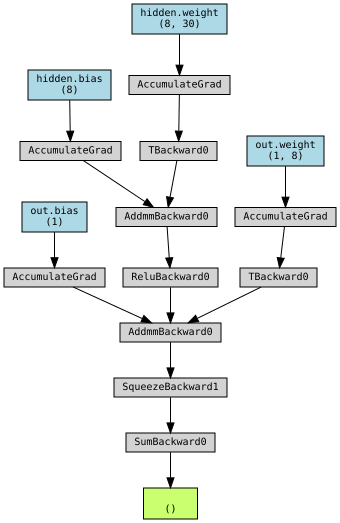

In [4]:
# 計算グラフを描く。torchviz の make_dot は、出力（z）から、逆伝播の道筋をたどって図にする
import shutil, subprocess, sys
from IPython.display import display                                 # 図を、セルの出力に出す関数（Jupyter・Colab・VS Code のノートブックにある）
try:
    import torchviz
except ImportError:                                               # 入っていなければ、ここで入れる（数秒）
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchviz==0.0.3"], check=True)
    import torchviz
if shutil.which("dot") is None:                                   # Graphviz の本体が無いと、図にできない（torchviz は、dot を呼ぶだけ）
    print("Graphviz (the 'dot' command) was not found, so the graph is skipped.")
    print("Install:  Ubuntu: sudo apt install graphviz  /  Mac: brew install graphviz  /  Windows: winget install graphviz  (then restart the notebook)")
else:
    zq = net(Ttr[:5])                                             # 順伝播を 1 回する。このとき、計算の記録が作られる
    graph = torchviz.make_dot(zq.sum(), params=dict(net.named_parameters()))     # sum() は、出力 5 個を 1 つにまとめて、1 本のグラフにするため
    display(graph)                                                # 青い箱 = 重み・バイアス、灰色の箱 = 計算。矢印は、逆伝播が進む向き

**読み方**: **青い箱**が、学習で直す数（`hidden.weight`＝W1 の 8×30、`hidden.bias`＝b1 の 8、`out.weight`＝W2 の 1×8、`out.bias`＝b2 の 1）、**灰色の箱**が計算、**一番下の緑の箱**が出力（ここでは 5 個の出力を `sum()` した 1 つの数）です。**灰色の名前**は、`AddmmBackward0` = 重み付き和（`nn.Linear`）、`ReluBackward0` = ReLU、`TBackward0` = 重みの転置、`SqueezeBackward1` = `squeeze(1)`、`SumBackward0` = 合計、`AccumulateGrad` = 「その重みの `.grad` に勾配を書き込む」所です（名前は PyTorch の版で少し変わることがあります）。**図の矢印は、順伝播の向き（上の重み → 下の出力）**に描かれています。**逆伝播は、その矢印を逆に（下の出力から上の重みへ）たどり、`AccumulateGrad` で、各重みの勾配を書き込みます**。入力 x の箱が無いのは、x の勾配は要らないからです（`requires_grad` が無い）。5 節の手書きの逆伝播は、**この道筋を、1 つずつ式にしたもの**です。

### ネットワークの全体像 — 重み W とバイアス b を、目で見る

下の図は、**同じネットワークの 3 つの見方**です。**左: つながり**（線の太さ = 重みの絶対値、青 = 正、橙 = 負。隠れ・出力の丸の色 = バイアス b）。**中央: W1（8×30）をそのまま並べた表**（1 行が隠れ素子 1 個の「30 個の特徴量への重み」）。**右: b1（8 個）、W2（8 個）、b2（1 個）**。**重みは、入力→隠れ層の線 1 本ずつに 1 つ、バイアスは、隠れ・出力の丸 1 個ずつに 1 つ**あり、**合計 257 個**です。まず、**学習前（でたらめな初期値）**を描きます。

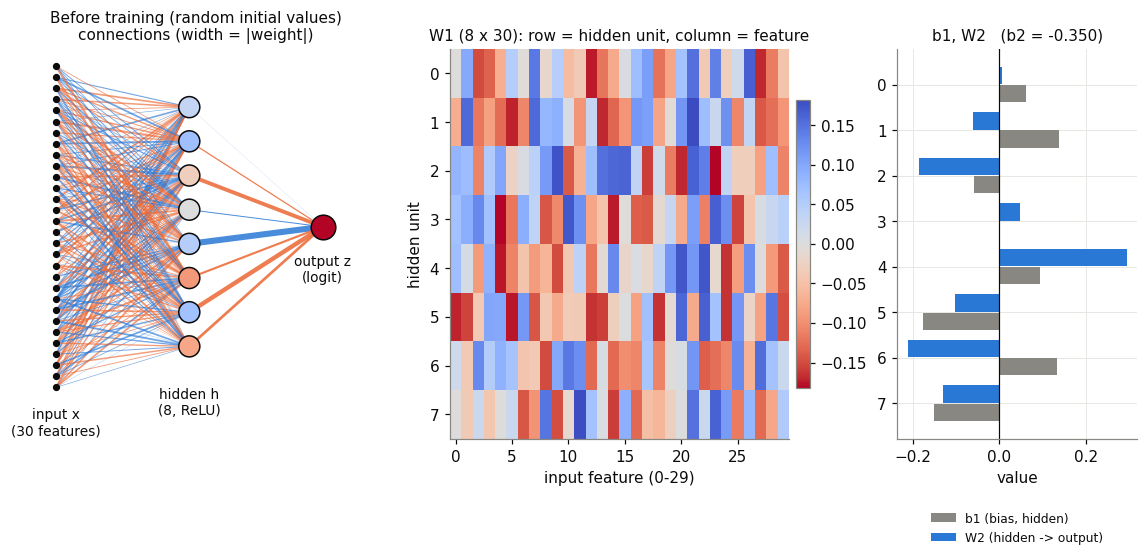

parameters shown: W1 (8, 30) + b1 (8,) + W2 (1, 8) + b2 (1,) = 257


In [5]:
# 重みとバイアスを描く関数（学習後にも使い回す）。内容は、表示だけで、計算には関係しない
def draw_net(model, title):
    W1_ = model.hidden.weight.detach().numpy(); b1_ = model.hidden.bias.detach().numpy()
    W2_ = model.out.weight.detach().numpy().ravel(); b2_ = float(model.out.bias.detach().numpy()[0])
    fig = plt.figure(figsize=(13, 4.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1.35, 0.9], wspace=0.28)
    ax = fig.add_subplot(gs[0]); ax.axis("off"); ax.set_title(title + "\nconnections (width = |weight|)", fontsize=10)
    yi = np.linspace(0.97, 0.03, 30); yh = np.linspace(0.85, 0.15, 8)       # 入力 30 個・隠れ 8 個の、縦の位置
    wmax = max(np.abs(W1_).max(), np.abs(W2_).max())
    for j in range(8):
        for i in range(30):
            w = W1_[j, i]; ax.plot([0, 1], [yi[i], yh[j]], color=BLUE if w > 0 else ORANGE, lw=2.2 * abs(w) / wmax, alpha=0.65, zorder=1)
        w = W2_[j]; ax.plot([1, 2], [yh[j], 0.5], color=BLUE if w > 0 else ORANGE, lw=4.0 * abs(w) / wmax, alpha=0.85, zorder=1)
    bmax = max(np.abs(b1_).max(), abs(b2_))
    ax.scatter(np.zeros(30), yi, s=14, color=INK, zorder=2)
    ax.scatter(np.ones(8), yh, s=190, c=b1_, cmap="coolwarm_r", vmin=-bmax, vmax=bmax, edgecolor=INK, zorder=2)      # 隠れ層の丸の色 = b1（青 = 正）
    ax.scatter([2], [0.5], s=260, c=[b2_], cmap="coolwarm_r", vmin=-bmax, vmax=bmax, edgecolor=INK, zorder=2)
    ax.text(0, -0.03, "input x\n(30 features)", ha="center", va="top", fontsize=9); ax.text(1, 0.03, "hidden h\n(8, ReLU)", ha="center", va="top", fontsize=9)
    ax.text(2, 0.42, "output z\n(logit)", ha="center", va="top", fontsize=9); ax.set_xlim(-0.2, 2.3); ax.set_ylim(-0.12, 1.02)
    ax1 = fig.add_subplot(gs[1]); im = ax1.imshow(W1_, cmap="coolwarm_r", vmin=-np.abs(W1_).max(), vmax=np.abs(W1_).max(), aspect="auto")
    ax1.grid(False); ax1.set_title("W1 (8 x 30): row = hidden unit, column = feature", fontsize=10); ax1.set_xlabel("input feature (0-29)"); ax1.set_ylabel("hidden unit")
    fig.colorbar(im, ax=ax1, fraction=0.04, pad=0.02)
    ax2 = fig.add_subplot(gs[2]); k = np.arange(8)
    ax2.barh(k + 0.2, b1_, height=0.38, color=MUTED, label="b1 (bias, hidden)"); ax2.barh(k - 0.2, W2_, height=0.38, color=BLUE, label="W2 (hidden -> output)")
    ax2.axvline(0, color=INK, lw=0.8); ax2.invert_yaxis(); ax2.set_yticks(k); ax2.set_xlabel("value"); ax2.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1, frameon=False)       # 凡例は、棒に重ならないよう、図の下に出す
    ax2.set_title(f"b1, W2   (b2 = {b2_:+.3f})", fontsize=10); plt.show()

draw_net(net, "Before training (random initial values)")
print("parameters shown: W1", tuple(net.hidden.weight.shape), "+ b1", tuple(net.hidden.bias.shape), "+ W2", tuple(net.out.weight.shape), "+ b2", tuple(net.out.bias.shape), "=", n_params)

**読み取り**: 学習前の重みは、**小さな乱数**で、青（正）と橙（負）がほぼ半々です。**これが、学習で「データに合う値」に変わっていきます**（6 節の最後に、同じ図を学習後に描いて比べます）。

## 5. 学習の仕組み — 損失、勾配降下、誤差逆伝播

学習は、次の 3 つの繰り返しです。

1. **損失（loss）を測る**: 予測と正解のずれを、1 つの数にする。ここでは**二値のクロスエントロピー**（悪性の確率 p と正解 y から、−[y·log p + (1−y)·log(1−p)]。正解に自信を持って外すと、損失が大きい）
2. **勾配を求める**: 損失を小さくするには、各重みを**どちらにどれだけ**動かせばよいか（損失を重みで偏微分したもの）。**これを効率よく求める方法が、誤差逆伝播**（出力側から入力側へ、微分の連鎖律を順にかけていく）
3. **重みを少し動かす（勾配降下）**: **新しい重み = 古い重み − 学習率 × 勾配**。学習率は、一歩の大きさ（人が決める）

**この節では、誤差逆伝播を、numpy で手で書きます。** PyTorch の自動微分（`backward()`）と一致することを確かめます。

### 順伝播と逆伝播の違い

**順伝播（forward）**と**逆伝播（backward）**は、**同じ 1 回の学習の中の、向きの違う 2 つの計算**です。

| | 順伝播 | 逆伝播（誤差逆伝播） |
|---|---|---|
| **向き** | **入力 → 出力** | **出力（損失）→ 入力** |
| **求めるもの** | **予測**（ロジット z）と、その**損失** | **損失を、各重み・バイアスで偏微分した値（勾配）** |
| **使うもの** | 重み W・バイアス b、入力 x | 順伝播で保存した**途中の値**（z1・h）と、ReLU の微分 |
| **いつ要るか** | **予測するときも、学習するときも** | **学習のときだけ**（予測だけなら不要） |
| **PyTorch** | `z = net(x)` | `loss.backward()`（勾配が、各重みの `.grad` に入る） |
| **コード（この節）** | `z1 = xn @ W1.T + b1; h = np.maximum(0, z1); z = ...` | `dz = (p - yn) / N` から `gW1 = ...` まで |

**1 回の更新の流れ**: **順伝播（予測と損失）→ 逆伝播（勾配）→ 重みの更新**。この 3 つを、データを変えながら繰り返すのが学習です。**逆伝播は、順伝播で計算した途中の値を使う**ので、**順伝播の途中の値は、捨てずに保存**しておきます（次のセルで、`z1`・`h` を残しているのはそのためです）。**予測だけをするとき**（検証・テスト・実際の運用）は、**逆伝播は要らない**ので、`with torch.no_grad():` で**記録を止めます**（計算が軽くなり、メモリも減ります）。

<details open data-ig="forward-backward" style="margin:14px 0">
  <summary style="cursor:pointer;font-weight:700">図で見る — 順伝播と逆伝播 — 向きの違い（クリックで閉じる・開く）</summary>
  <div style="overflow-x:auto;margin-top:10px;padding:8px;border:1px solid rgba(128,128,128,0.45);border-radius:6px">
<svg viewBox="0 0 830 330" width="100%" style="min-width:620px;display:block" role="img" aria-label="順伝播（入力から損失まで）と逆伝播（損失から重みまで）の流れの図">
  <text x="4" y="20" font-size="12.5" text-anchor="start" font-weight="700" fill="#2E9E94">順伝播（入力 → 出力 → 損失）。途中の値 z1・h は、逆伝播のために保存する</text>
  <rect x="4.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="44" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">入力 x</text>
  <text x="44" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(N, 30)</text>
  <line x1="85.0" y1="56.0" x2="96.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="96.0,56.0 90.6,58.6 90.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="97.0" y="34.0" width="80.0" height="44.0" rx="4" fill="#D9782F" fill-opacity="0.2" stroke="#D9782F" stroke-width="1.3"/>
  <text x="137" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">W1, b1</text>
  <text x="137" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(8, 30)・(8)</text>
  <line x1="178.0" y1="56.0" x2="189.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="189.0,56.0 183.6,58.6 183.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="190.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="230" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">z1</text>
  <text x="230" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(N, 8)</text>
  <line x1="271.0" y1="56.0" x2="282.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="282.0,56.0 276.6,58.6 276.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="283.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="323" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">ReLU</text>
  <text x="323" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(N, 8)</text>
  <line x1="364.0" y1="56.0" x2="375.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="375.0,56.0 369.6,58.6 369.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="376.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="416" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">h</text>
  <text x="416" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(N, 8)</text>
  <line x1="457.0" y1="56.0" x2="468.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="468.0,56.0 462.6,58.6 462.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="469.0" y="34.0" width="80.0" height="44.0" rx="4" fill="#D9782F" fill-opacity="0.2" stroke="#D9782F" stroke-width="1.3"/>
  <text x="509" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">W2, b2</text>
  <text x="509" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(1, 8)・(1)</text>
  <line x1="550.0" y1="56.0" x2="561.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="561.0,56.0 555.6,58.6 555.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="562.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="602" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">z</text>
  <text x="602" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">(N,)</text>
  <line x1="643.0" y1="56.0" x2="654.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="654.0,56.0 648.6,58.6 648.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="655.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="695" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">シグモイド</text>
  <text x="695" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">p (N,)</text>
  <line x1="736.0" y1="56.0" x2="747.0" y2="56.0" stroke="#2E9E94" stroke-width="1.8"/>
  <polygon points="747.0,56.0 741.6,58.6 741.6,53.4" fill="#2E9E94" fill-opacity="1.0"/>
  <rect x="748.0" y="34.0" width="80.0" height="44.0" rx="4" fill="currentColor" fill-opacity="0.08" stroke="currentColor" stroke-width="1.3"/>
  <text x="788" y="54" font-size="11.5" text-anchor="middle" font-weight="700" fill="currentColor">損失 L</text>
  <text x="788" y="71" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.85">1 つの数</text>
  <text x="4" y="112" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.85">損失 L は、予測 p と正解 y のずれ（例の平均）</text>
  <line x1="788.0" y1="78.0" x2="788.0" y2="144.0" stroke="#D9782F" stroke-width="1.4" stroke-dasharray="3 3"/>
  <line x1="788.0" y1="144.0" x2="784.0" y2="152.0" stroke="#D9782F" stroke-width="1.4"/>
  <polygon points="784.0,152.0 784.1,146.0 788.8,148.3" fill="#D9782F" fill-opacity="1.0"/>
  <line x1="784.0" y1="150.0" x2="44.0" y2="150.0" stroke="#D9782F" stroke-width="2.2"/>
  <line x1="145.0" y1="150.0" x2="44.0" y2="150.0" stroke="#D9782F" stroke-width="2.2"/>
  <polygon points="44.0,150.0 49.4,147.4 49.4,152.6" fill="#D9782F" fill-opacity="1.0"/>
  <text x="4" y="140" font-size="12.5" text-anchor="start" font-weight="700" fill="#D9782F">逆伝播（損失 → 重み）。各重みの勾配を、出力側から順に求める</text>
  <line x1="695.0" y1="150.0" x2="695.0" y2="164.0" stroke="#D9782F" stroke-width="1.4"/>
  <rect x="651.0" y="164.0" width="88.0" height="76.0" rx="4" fill="#D9782F" fill-opacity="0.13" stroke="#D9782F" stroke-width="1.3"/>
  <text x="695" y="184" font-size="12" text-anchor="middle" font-weight="700" fill="currentColor">dz</text>
  <text x="695" y="202" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">(N,)</text>
  <text x="695" y="224" font-size="9" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">= (p − y) / N</text>
  <line x1="509.0" y1="150.0" x2="509.0" y2="164.0" stroke="#D9782F" stroke-width="1.4"/>
  <rect x="465.0" y="164.0" width="88.0" height="76.0" rx="4" fill="#D9782F" fill-opacity="0.13" stroke="#D9782F" stroke-width="1.3"/>
  <text x="509" y="184" font-size="12" text-anchor="middle" font-weight="700" fill="currentColor">gW2, gb2</text>
  <text x="509" y="202" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">(1, 8)・(1)</text>
  <text x="509" y="224" font-size="9" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">= Σ dz · h</text>
  <line x1="416.0" y1="150.0" x2="416.0" y2="164.0" stroke="#D9782F" stroke-width="1.4"/>
  <rect x="372.0" y="164.0" width="88.0" height="76.0" rx="4" fill="#D9782F" fill-opacity="0.13" stroke="#D9782F" stroke-width="1.3"/>
  <text x="416" y="184" font-size="12" text-anchor="middle" font-weight="700" fill="currentColor">dh</text>
  <text x="416" y="202" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">(N, 8)</text>
  <text x="416" y="224" font-size="9" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">= dz · W2</text>
  <line x1="323.0" y1="150.0" x2="323.0" y2="164.0" stroke="#D9782F" stroke-width="1.4"/>
  <rect x="279.0" y="164.0" width="88.0" height="76.0" rx="4" fill="#D9782F" fill-opacity="0.13" stroke="#D9782F" stroke-width="1.3"/>
  <text x="323" y="184" font-size="12" text-anchor="middle" font-weight="700" fill="currentColor">dz1</text>
  <text x="323" y="202" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">(N, 8)</text>
  <text x="323" y="224" font-size="9" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">= dh × 1[z1>0]</text>
  <line x1="137.0" y1="150.0" x2="137.0" y2="164.0" stroke="#D9782F" stroke-width="1.4"/>
  <rect x="93.0" y="164.0" width="88.0" height="76.0" rx="4" fill="#D9782F" fill-opacity="0.13" stroke="#D9782F" stroke-width="1.3"/>
  <text x="137" y="184" font-size="12" text-anchor="middle" font-weight="700" fill="currentColor">gW1, gb1</text>
  <text x="137" y="202" font-size="9.5" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">(8, 30)・(8)</text>
  <text x="137" y="224" font-size="9" text-anchor="middle" font-weight="400" fill="currentColor" fill-opacity="0.9">= Σ dz1 · x</text>
  <text x="4" y="290" font-size="11.5" text-anchor="start" font-weight="700" fill="currentColor">勾配の形は、必ず、そのパラメータと同じ形（W1 は 8×30 なので gW1 も 8×30）。</text>
  <text x="4" y="310" font-size="11.5" text-anchor="start" font-weight="400" fill="currentColor">予測だけなら、順伝播だけでよい（逆伝播は学習のときだけ）。</text>
</svg>
  </div>
  <div style="margin-top:8px;font-size:0.85em">上の段（青緑の矢印）が順伝播、下の段（橙）が逆伝播です。形は、5 節の「配列の形で追う」の表と同じです。上の段の橙の箱（W1, b1 と W2, b2）が、学習で直す数です。下の段の橙の箱は、その勾配です。</div>
</details>

In [6]:
# 損失を、式どおりに手で計算し、PyTorch の関数と一致するか確かめる
with torch.no_grad():
    zt = net(Ttr)                                          # 訓練用全体のロジット
p = 1 / (1 + np.exp(-zt.numpy()))                          # シグモイド関数で確率に直す
loss_hand = float(np.mean(-(ytr * np.log(p) + (1 - ytr) * np.log(1 - p))))
loss_torch = nn.BCEWithLogitsLoss()(zt, ttr).item()        # PyTorch の二値クロスエントロピー（ロジットを受け取る版）
print("loss by hand :", round(loss_hand, 6))
print("loss by torch:", round(loss_torch, 6))
# 学習前の損失は、ln 2 ≈ 0.693（確率 0.5 でずっと答えるのと同じ）に近いはず
print("ln 2 =", round(float(np.log(2)), 6))

loss by hand : 0.672226
loss by torch: 0.672226
ln 2 = 0.693147


### 誤差逆伝播を、配列の形で追う

次のセルは、**N 例（N = 341）をまとめて**計算します。1 行ずつ、**何の形（shape）の配列か**と、**どの式か**を対応させて読みます。**`@` は行列の積**（`(a, b) @ (b, c)` は `(a, c)` の形になる）、`.T` は転置、`*` は同じ位置どうしの積です。**損失 L は、N 例の平均**なので、勾配には 1/N がかかります。

| 変数 | 形 | 意味・式 |
|---|---|---|
| `xn` | (N, 30) | 入力 x |
| `z1` | (N, 8) | 隠れ層の重み付き和 z1 = x·W1ᵀ + b1 |
| `h` | (N, 8) | ReLU のあと h = max(0, z1) |
| `z` | (N,) | 出力（ロジット）z = h·W2ᵀ + b2 |
| `p` | (N,) | 確率 p = シグモイド(z) |
| `dz` | (N,) | ∂L/∂z = (p − y)/N（BCE とシグモイドの組み合わせの結果） |
| `gW2` | (1, 8) | ∂L/∂W2 = Σₙ dzₙ · hₙ。`dz[:, None].T`（1, N）@ `h`（N, 8） |
| `gb2` | (1,) | ∂L/∂b2 = Σₙ dzₙ |
| `dh` | (N, 8) | ∂L/∂h = dz · W2。`dz[:, None]`（N, 1）@ `W2`（1, 8） |
| `dz1` | (N, 8) | ∂L/∂z1 = dh × 1[z1 > 0]（ReLU の微分。負だった所は 0） |
| `gW1` | (8, 30) | ∂L/∂W1 = Σₙ dz1ₙ · xₙ。`dz1.T`（8, N）@ `xn`（N, 30） |
| `gb1` | (8,) | ∂L/∂b1 = Σₙ dz1ₙ |

**形の見方**: **勾配の形は、必ず、そのパラメータと同じ形**になります（W1 は 8×30 なので、gW1 も 8×30）。**そうならなければ、式の向きが間違っています。** 例の方向（N）は、`@` の中で**足されて消えます**（Σₙ の意味）。

**このセルで求める勾配（`gW1` など）は、重みを動かすためには使いません。** **自動微分（`backward()`）の勾配と同じ値になるか**を確かめるだけです（このあとのセルの出力）。**重みを動かす更新は、次の「学習率」のセルで行い**、そこでは `loss.backward()` が求めた勾配を、`opt.step()` が使います。手書きの勾配は、自動微分と 1e-8 の差で一致するので、**手書きの勾配で更新しても、同じ動きになるはず**です（この節では、確かめていません）。

In [7]:
# 誤差逆伝播を、手で書く。出力側から、微分を順にかけていく。かっこの中は、配列の形（N は例の数）
N = len(ytr)
xn, yn = Ttr.numpy(), ytr.astype(float)                                        # xn: (N, 30)、yn: (N,)
z1 = xn @ W1.T + b1; h = np.maximum(0, z1); z = (h @ W2.T + b2).ravel(); p = 1 / (1 + np.exp(-z))   # 順伝播（保存しておく）。z1: (N, 8)、h: (N, 8)、z: (N,)、p: (N,)
dz = (p - yn) / N                                  # (N,)。損失の、出力 z での微分。BCE とシグモイドの組み合わせは、(p − y)/N になる
gW2 = dz[:, None].T @ h                            # (1, 8)。出力層の重みの勾配。(1, N) @ (N, 8)。例ごとの dz × h を、足し合わせる
gb2 = dz.sum(keepdims=True)                        # (1,)。出力層のバイアスの勾配
dh = dz[:, None] @ W2                              # (N, 8)。隠れ層の出力へ、さかのぼる。(N, 1) @ (1, 8)
dz1 = dh * (z1 > 0)                                # (N, 8)。ReLU の微分。負だった所（出力 0 にした所）は、勾配が通らない
gW1 = dz1.T @ xn                                   # (8, 30)。隠れ層の重みの勾配。(8, N) @ (N, 30)
gb1 = dz1.sum(axis=0)                              # (8,)。隠れ層のバイアスの勾配
# ここで求めた gW1 などは、このあと自動微分と照らすためだけに使う（重みは動かさない）。重みを動かすのは、次の「学習率」のセル

# PyTorch の自動微分で、同じ勾配を求める
net.zero_grad()
nn.BCEWithLogitsLoss()(net(Ttr), ttr).backward()
auto = {"W1": net.hidden.weight.grad.numpy(), "b1": net.hidden.bias.grad.numpy(),
        "W2": net.out.weight.grad.numpy(), "b2": net.out.bias.grad.numpy()}
hand = {"W1": gW1, "b1": gb1, "W2": gW2, "b2": gb2}
for k in hand:
    print(f"{k}: max |hand - autograd| = {np.abs(hand[k] - auto[k]).max():.2e}   (gradient scale {np.abs(auto[k]).max():.2e})")

W1: max |hand - autograd| = 6.66e-09   (gradient scale 6.24e-02)
b1: max |hand - autograd| = 1.87e-09   (gradient scale 2.16e-02)
W2: max |hand - autograd| = 1.53e-08   (gradient scale 5.30e-02)
b2: max |hand - autograd| = 6.92e-09   (gradient scale 4.11e-02)


In [8]:
# 数値微分でも確かめる。重みを ε だけ動かして損失の変化を見る方法。遅いが、微分の定義そのもの（ε = 1e-4 は人が決めた値）
eps = 1e-4
def loss_with_w1(i, j, delta):
    w = W1.astype(np.float64); w[i, j] += delta                       # W1 の (i, j) だけを動かす。計算は float64（倍精度）で行う。float32 だと、ε が小さいぶん丸め誤差が目立つため
    hh = np.maximum(0, xn.astype(np.float64) @ w.T + b1); zz = (hh @ W2.T + b2).ravel(); pp = 1 / (1 + np.exp(-zz))
    return float(np.mean(-(yn * np.log(pp) + (1 - yn) * np.log(1 - pp))))
i, j = 3, 7
numeric = (loss_with_w1(i, j, eps) - loss_with_w1(i, j, -eps)) / (2 * eps)
print(f"W1[{i},{j}] gradient: backprop {gW1[i, j]:.6f}   numeric {numeric:.6f}   autograd {auto['W1'][i, j]:.6f}")

W1[3,7] gradient: backprop -0.009962   numeric -0.009962   autograd -0.009962


**読み取り**: 学習前の損失は **0.672**（手計算も PyTorch も同じ）で、ln 2（0.693）に近い値です。**手で書いた誤差逆伝播の勾配は、自動微分と 1e-8 の差で一致**しました（勾配の大きさは 0.02〜0.06）。**数値微分（重みを少し動かして損失の変化を見る方法）とも、小数の 6 桁目まで一致**します（W1[3,7]: −0.009962）。**誤差逆伝播は、微分の連鎖律を出力側から順にかけているだけ**で、`backward()` が中でしていることです。

**ReLU の微分**（`z1 > 0`）が効くところに注目します。**負だった所は勾配が 0** で、その隠れ素子につながる重みは、その例では動きません。

### 学習率 — 一歩の大きさ

勾配が分かったら、**重みを「勾配の逆向きに、学習率だけ」動かす**のを繰り返します。**学習率が小さすぎると進まず、大きすぎると行き過ぎて発散します**。次で、学習率を 5 つに変えて、**200 回の更新**を比べます。

 learning rate  loss before 1st update  loss after 200 updates first update with nan
         0.001                   0.672                   0.647                 never
         0.010                   0.672                   0.406                 never
         0.100                   0.672                   0.068                 never
         1.000                   0.672                   0.015                 never
        10.000                   0.672                     NaN                    23


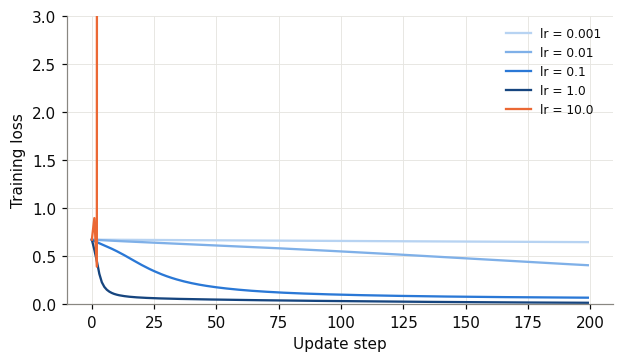

In [9]:
# 全データを使う勾配降下（SGD、モーメンタム無し）を、学習率を変えて 200 回行う。200 は人が決めた値
def train_full_batch(lr, steps=200, seed=0):
    torch.manual_seed(seed)                                   # どの学習率でも、同じ初期値から始める（比べるため）
    m = ShallowNet()
    opt = torch.optim.SGD(m.parameters(), lr=lr)              # 新しい重み = 古い重み − lr × 勾配
    L = nn.BCEWithLogitsLoss(); hist = []
    for _ in range(steps):
        opt.zero_grad()                                       # 前回の勾配を消す（消さないと足される）
        loss = L(m(Ttr), ttr); loss.backward()                # 損失を測り、誤差逆伝播で勾配を求める
        opt.step()                                            # 重みを更新する
        hist.append(loss.item())
    return hist

lrs = [0.001, 0.01, 0.1, 1.0, 10.0]
curves = {lr: train_full_batch(lr) for lr in lrs}
first_bad = [next((k + 1 for k, v in enumerate(curves[l]) if not np.isfinite(v)), "never") for l in lrs]      # 損失が nan（数でなくなる）になった最初の更新回数。ならなければ never
print(pd.DataFrame({"learning rate": lrs, "loss before 1st update": [round(curves[l][0], 3) for l in lrs],
                    "loss after 200 updates": [round(curves[l][-1], 3) for l in lrs], "first update with nan": first_bad}).to_string(index=False))
# 図の読み方: 横軸は更新の回数、縦軸は訓練用の損失（低いほどよい）。線の色は学習率。
# 小さい学習率（青の薄い線）はなかなか下がらず、0.1〜1 は速く下がる。大きすぎる 10（オレンジ）は、下がらずに暴れる。
fig, ax = plt.subplots(figsize=(6.4, 3.4))
shade = {0.001: "#b7d3f2", 0.01: "#7fb0e8", 0.1: BLUE, 1.0: "#16457f", 10.0: ORANGE}
for lr in lrs:
    ax.plot(curves[lr], color=shade[lr], label=f"lr = {lr}")
ax.set_ylim(0, 3); ax.set_xlabel("Update step"); ax.set_ylabel("Training loss"); ax.legend(frameon=False, fontsize=8)
plt.show()

**読み取り**: 200 回の更新のあとの損失は、学習率 0.001 で **0.647**（ほとんど下がらない）、0.01 で **0.406**、0.1 で **0.068**、1.0 で **0.015** です。**10 では、23 回目の更新で損失が nan（数ではなくなった）になり、以後は学習できません**（図では、オレンジの線が最初の数回で画面の上に消えます）。

**学習率は、大きいほどよい、でも小さいほどよい、でもありません。** この問題では 0.1〜1 が速く、10 は発散しました。**ただし、「最も損失が小さい学習率」を選ぶ作業は、検証用で行います**（訓練用の損失だけでは、過学習が見えません。次の節）。

## 6. 訓練を検証する — 誤差・精度の曲線、過学習、早期終了

**訓練用の誤差が下がっているだけでは、学習できたと言えません**（第7回 9 節）。**検証用での誤差と精度を、同じ図に重ねて見ます。**

実際の訓練は、**ミニバッチ**で行います。**全データを一度に使わず、32 例ずつ取り出して、そのたびに重みを更新**します（人が決めた値。大きなデータでは、全部を一度に計算できないため）。**全データを 1 周すると 1 エポック**です。最適化は **Adam**（学習率を、重みごとに自動で調整する）を使います。

final epoch   : train loss 0.001, val loss 0.069, train acc 1.000, val acc 0.982
best val loss : epoch 19 (val loss 0.030)


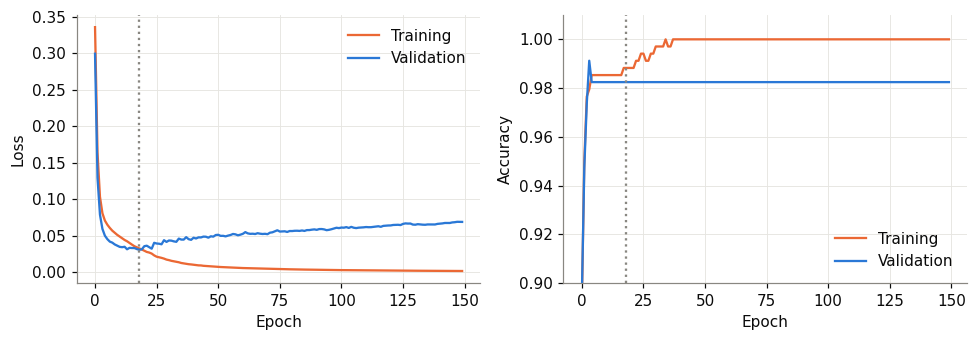

In [10]:
# 訓練の関数。1 エポックごとに、訓練用・検証用の損失と正解率を記録する
def accuracy(m, T, t):
    with torch.no_grad(): return ((m(T) > 0).float() == t).float().mean().item()      # ロジット > 0 を悪性と答える

def train(seed=0, epochs=150, lr=0.01, batch=32, y_train=None, model=None, T=None):
    torch.manual_seed(seed)                                   # 初期値とミニバッチの順序を固定
    m = model if model is not None else ShallowNet()
    Tx = Ttr if T is None else T
    yy = ttr if y_train is None else y_train
    opt = torch.optim.Adam(m.parameters(), lr=lr)             # lr = 0.01、エポック 150 は人が決めた値
    L = nn.BCEWithLogitsLoss(); hist = []; best = (1e9, None, -1)
    for ep in range(epochs):
        m.train()
        order = torch.randperm(len(Tx))                       # 毎エポック、順序をシャッフルする
        for i in range(0, len(order), batch):
            idx = order[i:i + batch]
            opt.zero_grad(); L(m(Tx[idx]), yy[idx]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            row = (L(m(Tx), yy).item(), L(m(Tva), tva).item(), accuracy(m, Tx, yy), accuracy(m, Tva, tva))
        hist.append(row)
        if row[1] < best[0]: best = (row[1], copy.deepcopy(m.state_dict()), ep)      # 検証用の損失が最小の重みを、とっておく（早期終了）
    return m, np.array(hist), best

net6, H, best = train()
print("final epoch   : train loss %.3f, val loss %.3f, train acc %.3f, val acc %.3f" % tuple(H[-1]))
print("best val loss : epoch %d (val loss %.3f)" % (best[2] + 1, best[0]))
# 図の読み方: 左は損失（低いほどよい）、右は正解率。横軸はエポック。オレンジは訓練用、青は検証用。縦の点線は、検証用の損失が最小だったエポック。
# 訓練用（オレンジ）は下がり続けるのに、検証用（青）の損失が途中から上がれば、そこから先は「覚えているだけ」（過学習）。
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (a, b), name in zip(axs, [(0, 1), (2, 3)], ["Loss", "Accuracy"]):
    ax.plot(H[:, a], color=ORANGE, label="Training"); ax.plot(H[:, b], color=BLUE, label="Validation")
    ax.axvline(best[2], color=MUTED, ls=":"); ax.set_xlabel("Epoch"); ax.set_ylabel(name); ax.legend(frameon=False)
axs[1].set_ylim(0.9, 1.01)
plt.tight_layout(); plt.show()

**読み取り**: **訓練用の損失（オレンジ）は 150 エポックまで下がり続け、最後は 0.001** です。**検証用の損失（青）は、19 エポックで最小（0.030）になり、そのあと上がって 0.069** になります。**これが過学習**です。

**正解率（右）は、ほとんど変わりません。** 検証用は 0.982 のまま、訓練用は 1.000 に上がります。**正解率だけを見ていると、過学習に気づけません。損失の曲線は、気づける**ことが、ここで分かります（検証用が 114 例だけで、正解率は 1 例が 0.9% なので、粗い指標でもあります）。

**早期終了**は、検証用の損失が最小だったエポックの重みを、とっておく方法です（`best`）。**ここでは「どこで止めるか」にも検証用を使っています**。検証用を使う回数が増えるので、**テスト用は、さらに大事に、最後まで取っておきます**。

In [11]:
# 早期終了: 検証用の損失が最小だったエポックの重みに戻して、テスト用に「1 回だけ」出す。ここまで、テスト用は一度も使っていない
final = ShallowNet(); final.load_state_dict(best[1]); final.eval()
with torch.no_grad():
    zte = final(Tte).numpy()
pred = (zte > 0).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
auc_dl = roc_auc_score(yte, zte)

# 比べる相手: 第6回のロジスティック回帰。同じ訓練用・同じ標準化で学習する（検証用は使わない）
lr_model = LogisticRegression(max_iter=1000).fit(scaler.transform(Xtr), ytr)
p_lr = lr_model.predict_proba(scaler.transform(Xte))[:, 1]
tn2, fp2, fn2, tp2 = confusion_matrix(yte, (p_lr > 0.5).astype(int)).ravel()
rows = [["Shallow network (8 hidden)", tp, tp + fn, tn, tn + fp, round((tp + tn) / len(yte), 4), round(auc_dl, 4)],
        ["Logistic regression", tp2, tp2 + fn2, tn2, tn2 + fp2, round((tp2 + tn2) / len(yte), 4), round(roc_auc_score(yte, p_lr), 4)]]
print(pd.DataFrame(rows, columns=["model", "TP", "malignant", "TN", "benign", "accuracy", "AUC"]).to_string(index=False))

                     model  TP  malignant  TN  benign  accuracy    AUC
Shallow network (8 hidden)  40         42  67      72    0.9386 0.9914
       Logistic regression  40         42  70      72    0.9649 0.9921


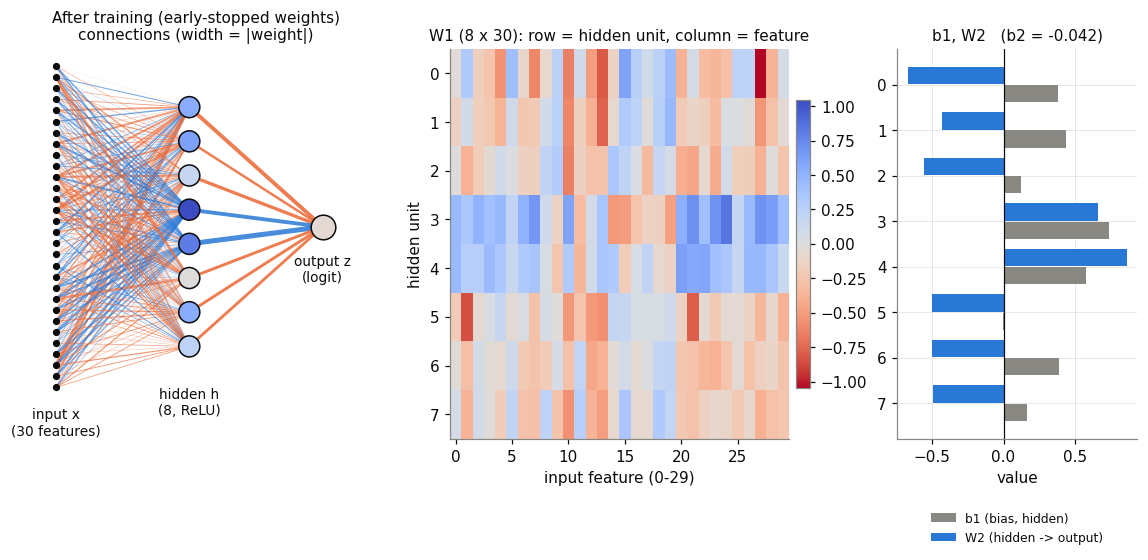

In [12]:
# 同じ図を、学習後（検証用の損失が最小だったエポックの重み）に描く。4 節の図と、見比べる
draw_net(final, "After training (early-stopped weights)")

**読み取り**: 学習後は、**重みの大きさの幅が、学習前の約 ±0.18 から、約 ±1.0 へ広がりました**（色の帯の端の値）。**学習前と学習後で、色の目盛り（右の色の帯）の幅が違う**ことに注意してください（図ごとに、その図の最大値に合わせています。同じ色でも、同じ大きさの重みとは限りません）。

In [13]:
# 乱数（初期値とミニバッチの順序）を変えて、10 回学習し直す。1 回の成績を、そのまま報告しない（第6回の約束 3）
accs, aucs, stops = [], [], []
for s in range(10):                                           # 10 回は人が決めた値
    m, Hs, bs = train(seed=s)
    f = ShallowNet(); f.load_state_dict(bs[1]); f.eval()
    with torch.no_grad(): zz = f(Tte).numpy()
    accs.append(((zz > 0).astype(int) == yte).mean()); aucs.append(roc_auc_score(yte, zz)); stops.append(bs[2] + 1)
print("test accuracy over 10 runs: mean %.4f, min %.4f, max %.4f" % (np.mean(accs), np.min(accs), np.max(accs)))
print("test AUC      over 10 runs: mean %.4f, min %.4f, max %.4f" % (np.mean(aucs), np.min(aucs), np.max(aucs)))
print("early-stopping epoch over 10 runs:", stops)

test accuracy over 10 runs: mean 0.9360, min 0.9211, max 0.9649
test AUC      over 10 runs: mean 0.9908, min 0.9881, max 0.9931
early-stopping epoch over 10 runs: [19, 24, 30, 28, 20, 18, 22, 22, 16, 23]


**読み取り**: **テスト用（114 例）の成績は、ネットワークが感度 40/42・特異度 67/72・AUC 0.991。ロジスティック回帰が、感度 40/42・特異度 70/72・AUC 0.992** です。**この表データでは、ネットワークはロジスティック回帰より良くなっていません**（差は、特異度で 3 例）。**「深層学習だから精度が高い」とは言えない**例です。

**10 回の学習で、テスト用の正解率は平均 0.936（最小 0.921、最大 0.965）、AUC は平均 0.991（0.988〜0.993）**。**学習のたびに、正解率が 5 例ぶん（0.921〜0.965）動きます**。**止まったエポックも 16〜30 とばらつきます**。上の 1 回（0.939）は、その幅の中にあります。**1 回の学習の成績を、そのまま報告しない**（第6回の約束 3）。

### 負例 — ラベルをでたらめにすると、何が起きるか

**深層学習は、覚える力が強い**ことを確かめます。**正解ラベルを、訓練用でだけシャッフル**して（特徴量とラベルの関係を壊す）、**隠れ層を大きくした**ネットワーク（256 個）で学習します。**何も学べないはずなのに、訓練用の正解率はどうなるでしょうか。**

In [14]:
# 訓練用のラベルを、でたらめに並べ替える（検証用のラベルはそのまま）。並べ替え方を変えて 8 回くり返す（1 回では、たまたまの値かもしれないため。8 は人が決めた値）。256 は、覚えられるだけの大きさにするために、人が決めた値
res = []
for gs in range(8):
    g = torch.Generator().manual_seed(gs)
    shuffled = ttr[torch.randperm(len(ttr), generator=g)]
    torch.manual_seed(0)
    big = ShallowNet(n_hidden=256)
    mb, Hb, _ = train(model=big, y_train=shuffled, epochs=300, lr=0.01)
    with torch.no_grad(): auc_b = roc_auc_score(yva, big(Tva).numpy())
    res.append((Hb[-1, 2], Hb[-1, 3], auc_b))
res = np.array(res)
print("shuffled labels, hidden=256, 300 epochs, 8 different shuffles")
print("  training accuracy  : mean %.3f (min %.3f, max %.3f)" % (res[:, 0].mean(), res[:, 0].min(), res[:, 0].max()))
print("  validation accuracy: mean %.3f (min %.3f, max %.3f)   [always answering benign: %.3f]" % (res[:, 1].mean(), res[:, 1].min(), res[:, 1].max(), 1 - yva.mean()))
print("  validation AUC     : mean %.3f (min %.3f, max %.3f)   [no information: 0.5]" % (res[:, 2].mean(), res[:, 2].min(), res[:, 2].max()))

shuffled labels, hidden=256, 300 epochs, 8 different shuffles
  training accuracy  : mean 1.000 (min 1.000, max 1.000)
  validation accuracy: mean 0.530 (min 0.386, max 0.693)   [always answering benign: 0.623]
  validation AUC     : mean 0.460 (min 0.257, max 0.606)   [no information: 0.5]


**読み取り**: **正解をでたらめにしても、訓練用の正解率は、8 回とも 1.000** になります。**特徴量とラベルの間に何の関係も無いのに、ネットワークは 341 例を全部覚えました**。**検証用の正解率は平均 0.530（0.386〜0.693）、AUC は平均 0.460（0.257〜0.606）で、当てずっぽう（0.5）と区別できません**。

**だから、「訓練用で 1.000」は、何も保証しません**。深層学習は、**覚える力が非常に強い**ので、**検証用・テスト用での成績だけが、学習できたことの証拠**です（第7回 9 節の、より極端な例）。

## 7. 活性化関数と損失関数 — 部品の選び方

ネットワークを作るとき、**人が選ぶ部品**が 2 つあります。**層の間に挟む「活性化関数」**と、**出力につなぐ「出力の関数と損失関数」**です。5 節では、損失（二値のクロスエントロピー）と、ReLU の微分を使いました。この節では、**どんな選択肢があり、何を基準に選ぶか**を、コードで確かめます。

**この節の最後の「参考」は、実行しない解説です**（読むだけ）。

### 活性化関数と、その微分 — 逆伝播で「毎回かかる」もの

隠れ層の ReLU のように、**重み付き和のあとに通す関数を「活性化関数」**といいます。**線形（重み付き和）だけを何層重ねても、結局 1 つの線形な式にまとまってしまう**ので、**間に曲がった関数を挟む**から、層を重ねる意味が出ます。

**誤差逆伝播では、層をさかのぼるたびに「活性化関数の微分」がかかります**（5 節の手書きの逆伝播の `dz1 = dh * (z1 > 0)` が、ReLU の微分）。だから、**微分の形が、学習のしやすさを決めます**。

| 関数 | 式 | 微分 | 特徴 |
|---|---|---|---|
| シグモイド | 1/(1+e⁻ˣ) | **s(1−s)**（最大 0.25） | 0〜1 に押し込む。**大きい・小さい入力では、微分がほぼ 0**。層を重ねると、**0.25 を何度もかけるので、勾配が消える**（勾配消失）。いまは、主に**出力の確率**に使う |
| tanh | (eˣ−e⁻ˣ)/(eˣ+e⁻ˣ) | **1−tanh²**（最大 1） | −1〜1。中心が 0 で、シグモイドより学びやすいが、**両端では、やはり微分がほぼ 0** |
| **ReLU** | max(0, x) | **x>0 なら 1、x<0 なら 0** | 計算が軽く、**正の側では勾配が減らない**ので、深いネットワークが学べる。**負の側は勾配が 0**（その素子の重みは、その例では動かない。**いつも負になった素子は、学習が止まる ＝ 「死んだ ReLU」**） |
| Leaky ReLU | x>0 なら x、x<0 なら 0.1x（0.1 は例） | **1 または 0.1** | 負の側にも、**わずかに勾配を通す** |
| GELU | x·Φ(x)（Φ は標準正規分布の累積分布） | Φ(x) + x·φ(x) | **なめらかな ReLU**。Transformer（第9回）でよく使う |

**微分の「かかり方」の目安**: **最良の場合でも、シグモイドの微分は 0.25** なので、**10 層で 0.25¹⁰ ≈ 1e-6**（勾配は、入力に近い層ほど、ほぼ 0）。**ReLU は、正の側なら 1 のままで、10 層でも 1¹⁰ = 1** です。**これが、2010 年代に ReLU が広まった理由のひとつ**とされます（理由のすべてではありません）。

<details open data-ig="activations" style="margin:14px 0">
  <summary style="cursor:pointer;font-weight:700">図で見る — 活性化関数 5 つ — 形と、逆伝播でかかる微分（クリックで閉じる・開く）</summary>
  <div style="overflow-x:auto;margin-top:10px;padding:8px;border:1px solid rgba(128,128,128,0.45);border-radius:6px">
<svg viewBox="0 0 828 258" width="100%" style="min-width:620px;display:block" role="img" aria-label="活性化関数 5 つの、関数（実線）と微分（点線）を並べたパネル">
  <rect x="0.0" y="0.0" width="160.0" height="218.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">シグモイド</text>
  <rect x="14.0" y="34.0" width="132.0" height="62.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <line x1="14.0" y1="96.0" x2="146.0" y2="96.0" stroke="currentColor" stroke-width="0.6" stroke-opacity="0.35"/>
  <path d="M 14.0 94.9 L 15.7 94.8 L 17.3 94.6 L 18.9 94.5 L 20.6 94.4 L 22.2 94.2 L 23.9 94.0 L 25.6 93.8 L 27.2 93.6 L 28.8 93.3 L 30.5 93.1 L 32.2 92.8 L 33.8 92.4 L 35.4 92.1 L 37.1 91.7 L 38.8 91.3 L 40.4 90.8 L 42.1 90.4 L 43.7 89.8 L 45.3 89.2 L 47.0 88.6 L 48.6 87.9 L 50.3 87.2 L 51.9 86.4 L 53.6 85.6 L 55.2 84.7 L 56.9 83.7 L 58.6 82.7 L 60.2 81.6 L 61.9 80.5 L 63.5 79.3 L 65.2 78.1 L 66.8 76.8 L 68.4 75.4 L 70.1 74.0 L 71.8 72.6 L 73.4 71.1 L 75.1 69.6 L 76.7 68.1 L 78.3 66.5 L 80.0 65.0 L 81.6 63.5 L 83.3 61.9 L 85.0 60.4 L 86.6 58.9 L 88.2 57.4 L 89.9 56.0 L 91.5 54.6 L 93.2 53.2 L 94.9 51.9 L 96.5 50.7 L 98.1 49.5 L 99.8 48.4 L 101.5 47.3 L 103.1 46.3 L 104.8 45.3 L 106.4 44.4 L 108.0 43.6 L 109.7 42.8 L 111.4 42.1 L 113.0 41.4 L 114.6 40.8 L 116.3 40.2 L 118.0 39.6 L 119.6 39.2 L 121.2 38.7 L 122.9 38.3 L 124.5 37.9 L 126.2 37.6 L 127.9 37.2 L 129.5 36.9 L 131.1 36.7 L 132.8 36.4 L 134.4 36.2 L 136.1 36.0 L 137.8 35.8 L 139.4 35.6 L 141.1 35.5 L 142.7 35.4 L 144.3 35.2 L 146.0 35.1" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <text x="14" y="108" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.8">f(x)</text>
  <rect x="14.0" y="118.0" width="132.0" height="52.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 14.0 164.0 L 15.7 163.9 L 17.3 163.9 L 18.9 163.8 L 20.6 163.7 L 22.2 163.6 L 23.9 163.5 L 25.6 163.4 L 27.2 163.3 L 28.8 163.1 L 30.5 163.0 L 32.2 162.8 L 33.8 162.7 L 35.4 162.5 L 37.1 162.3 L 38.8 162.1 L 40.4 161.9 L 42.1 161.7 L 43.7 161.4 L 45.3 161.1 L 47.0 160.9 L 48.6 160.6 L 50.3 160.3 L 51.9 159.9 L 53.6 159.6 L 55.2 159.3 L 56.9 158.9 L 58.6 158.6 L 60.2 158.2 L 61.9 157.9 L 63.5 157.6 L 65.2 157.3 L 66.8 156.9 L 68.4 156.7 L 70.1 156.4 L 71.8 156.2 L 73.4 156.0 L 75.1 155.9 L 76.7 155.7 L 78.3 155.7 L 80.0 155.7 L 81.6 155.7 L 83.3 155.7 L 85.0 155.9 L 86.6 156.0 L 88.2 156.2 L 89.9 156.4 L 91.5 156.7 L 93.2 156.9 L 94.9 157.3 L 96.5 157.6 L 98.1 157.9 L 99.8 158.2 L 101.5 158.6 L 103.1 158.9 L 104.8 159.3 L 106.4 159.6 L 108.0 159.9 L 109.7 160.3 L 111.4 160.6 L 113.0 160.9 L 114.6 161.1 L 116.3 161.4 L 118.0 161.7 L 119.6 161.9 L 121.2 162.1 L 122.9 162.3 L 124.5 162.5 L 126.2 162.7 L 127.9 162.8 L 129.5 163.0 L 131.1 163.1 L 132.8 163.3 L 134.4 163.4 L 136.1 163.5 L 137.8 163.6 L 139.4 163.7 L 141.1 163.8 L 142.7 163.9 L 144.3 163.9 L 146.0 164.0" fill="none" stroke="#D9782F" stroke-width="2.0" stroke-dasharray="4 3"/>
  <text x="14" y="182" font-size="10" text-anchor="start" font-weight="400" fill="#D9782F" fill-opacity="0.95">微分</text>
  <text x="146" y="182" font-size="10" text-anchor="end" font-weight="700" fill="currentColor">最大 0.25</text>
  <text x="8" y="200" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">0〜1 に押し込む。</text>
  <text x="8" y="214" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">両端は微分がほぼ 0</text>
  <rect x="167.0" y="0.0" width="160.0" height="218.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="177" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">tanh</text>
  <rect x="181.0" y="34.0" width="132.0" height="62.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <line x1="181.0" y1="65.0" x2="313.0" y2="65.0" stroke="currentColor" stroke-width="0.6" stroke-opacity="0.35"/>
  <path d="M 181.0 96.0 L 182.7 96.0 L 184.3 96.0 L 185.9 96.0 L 187.6 96.0 L 189.2 95.9 L 190.9 95.9 L 192.6 95.9 L 194.2 95.9 L 195.8 95.9 L 197.5 95.8 L 199.2 95.8 L 200.8 95.8 L 202.4 95.7 L 204.1 95.7 L 205.8 95.6 L 207.4 95.5 L 209.1 95.4 L 210.7 95.2 L 212.3 95.1 L 214.0 94.9 L 215.7 94.6 L 217.3 94.4 L 218.9 94.0 L 220.6 93.6 L 222.2 93.1 L 223.9 92.4 L 225.6 91.7 L 227.2 90.8 L 228.8 89.8 L 230.5 88.6 L 232.2 87.2 L 233.8 85.6 L 235.4 83.7 L 237.1 81.6 L 238.8 79.3 L 240.4 76.8 L 242.1 74.0 L 243.7 71.1 L 245.3 68.1 L 247.0 65.0 L 248.6 61.9 L 250.3 58.9 L 251.9 56.0 L 253.6 53.2 L 255.2 50.7 L 256.9 48.4 L 258.6 46.3 L 260.2 44.4 L 261.9 42.8 L 263.5 41.4 L 265.1 40.2 L 266.8 39.2 L 268.4 38.3 L 270.1 37.6 L 271.8 36.9 L 273.4 36.4 L 275.1 36.0 L 276.7 35.6 L 278.4 35.4 L 280.0 35.1 L 281.6 34.9 L 283.3 34.8 L 284.9 34.6 L 286.6 34.5 L 288.2 34.4 L 289.9 34.3 L 291.6 34.3 L 293.2 34.2 L 294.9 34.2 L 296.5 34.2 L 298.1 34.1 L 299.8 34.1 L 301.4 34.1 L 303.1 34.1 L 304.8 34.1 L 306.4 34.0 L 308.1 34.0 L 309.7 34.0 L 311.4 34.0 L 313.0 34.0" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <text x="181" y="108" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.8">f(x)</text>
  <rect x="181.0" y="118.0" width="132.0" height="52.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 181.0 164.6 L 182.7 164.6 L 184.3 164.5 L 185.9 164.5 L 187.6 164.5 L 189.2 164.5 L 190.9 164.5 L 192.6 164.4 L 194.2 164.4 L 195.8 164.3 L 197.5 164.3 L 199.2 164.2 L 200.8 164.1 L 202.4 164.0 L 204.1 163.8 L 205.8 163.7 L 207.4 163.5 L 209.1 163.2 L 210.7 162.9 L 212.3 162.5 L 214.0 162.1 L 215.7 161.6 L 217.3 160.9 L 218.9 160.1 L 220.6 159.2 L 222.2 158.1 L 223.9 156.9 L 225.6 155.4 L 227.2 153.7 L 228.8 151.7 L 230.5 149.6 L 232.2 147.2 L 233.8 144.6 L 235.4 141.9 L 237.1 139.1 L 238.8 136.4 L 240.4 133.9 L 242.1 131.8 L 243.7 130.2 L 245.3 129.1 L 247.0 128.8 L 248.6 129.1 L 250.3 130.2 L 251.9 131.8 L 253.6 133.9 L 255.2 136.4 L 256.9 139.1 L 258.6 141.9 L 260.2 144.6 L 261.9 147.2 L 263.5 149.6 L 265.1 151.7 L 266.8 153.7 L 268.4 155.4 L 270.1 156.9 L 271.8 158.1 L 273.4 159.2 L 275.1 160.1 L 276.7 160.9 L 278.4 161.6 L 280.0 162.1 L 281.6 162.5 L 283.3 162.9 L 284.9 163.2 L 286.6 163.5 L 288.2 163.7 L 289.9 163.8 L 291.6 164.0 L 293.2 164.1 L 294.9 164.2 L 296.5 164.3 L 298.1 164.3 L 299.8 164.4 L 301.4 164.4 L 303.1 164.5 L 304.8 164.5 L 306.4 164.5 L 308.1 164.5 L 309.7 164.5 L 311.4 164.6 L 313.0 164.6" fill="none" stroke="#D9782F" stroke-width="2.0" stroke-dasharray="4 3"/>
  <text x="181" y="182" font-size="10" text-anchor="start" font-weight="400" fill="#D9782F" fill-opacity="0.95">微分</text>
  <text x="313" y="182" font-size="10" text-anchor="end" font-weight="700" fill="currentColor">最大 1</text>
  <text x="175" y="200" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">−1〜1。中心が 0。</text>
  <text x="175" y="214" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">両端は微分がほぼ 0</text>
  <rect x="334.0" y="0.0" width="160.0" height="218.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="344" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">ReLU</text>
  <rect x="348.0" y="34.0" width="132.0" height="62.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <line x1="348.0" y1="89.1" x2="480.0" y2="89.1" stroke="currentColor" stroke-width="0.6" stroke-opacity="0.35"/>
  <path d="M 348.0 89.1 L 349.6 89.1 L 351.3 89.1 L 352.9 89.1 L 354.6 89.1 L 356.2 89.1 L 357.9 89.1 L 359.6 89.1 L 361.2 89.1 L 362.9 89.1 L 364.5 89.1 L 366.1 89.1 L 367.8 89.1 L 369.4 89.1 L 371.1 89.1 L 372.8 89.1 L 374.4 89.1 L 376.1 89.1 L 377.7 89.1 L 379.4 89.1 L 381.0 89.1 L 382.6 89.1 L 384.3 89.1 L 385.9 89.1 L 387.6 89.1 L 389.2 89.1 L 390.9 89.1 L 392.6 89.1 L 394.2 89.1 L 395.9 89.1 L 397.5 89.1 L 399.1 89.1 L 400.8 89.1 L 402.4 89.1 L 404.1 89.1 L 405.8 89.1 L 407.4 89.1 L 409.1 89.1 L 410.7 89.1 L 412.4 89.1 L 414.0 89.1 L 415.6 87.7 L 417.3 86.4 L 418.9 85.0 L 420.6 83.6 L 422.2 82.2 L 423.9 80.8 L 425.6 79.5 L 427.2 78.1 L 428.9 76.7 L 430.5 75.3 L 432.1 74.0 L 433.8 72.6 L 435.4 71.2 L 437.1 69.8 L 438.8 68.4 L 440.4 67.1 L 442.1 65.7 L 443.7 64.3 L 445.4 62.9 L 447.0 61.6 L 448.6 60.2 L 450.3 58.8 L 451.9 57.4 L 453.6 56.0 L 455.2 54.7 L 456.9 53.3 L 458.6 51.9 L 460.2 50.5 L 461.9 49.2 L 463.5 47.8 L 465.1 46.4 L 466.8 45.0 L 468.4 43.6 L 470.1 42.3 L 471.8 40.9 L 473.4 39.5 L 475.1 38.1 L 476.7 36.8 L 478.4 35.4 L 480.0 34.0" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <text x="348" y="108" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.8">f(x)</text>
  <rect x="348.0" y="118.0" width="132.0" height="52.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 348.0 164.6 L 349.6 164.6 L 351.3 164.6 L 352.9 164.6 L 354.6 164.6 L 356.2 164.6 L 357.9 164.6 L 359.6 164.6 L 361.2 164.6 L 362.9 164.6 L 364.5 164.6 L 366.1 164.6 L 367.8 164.6 L 369.4 164.6 L 371.1 164.6 L 372.8 164.6 L 374.4 164.6 L 376.1 164.6 L 377.7 164.6 L 379.4 164.6 L 381.0 164.6 L 382.6 164.6 L 384.3 164.6 L 385.9 164.6 L 387.6 164.6 L 389.2 164.6 L 390.9 164.6 L 392.6 164.6 L 394.2 164.6 L 395.9 164.6 L 397.5 164.6 L 399.1 164.6 L 400.8 164.6 L 402.4 164.6 L 404.1 164.6 L 405.8 164.6 L 407.4 164.6 L 409.1 164.6 L 410.7 164.6 L 412.4 164.6 L 414.0 164.6 L 415.6 128.8 L 417.3 128.8 L 418.9 128.8 L 420.6 128.8 L 422.2 128.8 L 423.9 128.8 L 425.6 128.8 L 427.2 128.8 L 428.9 128.8 L 430.5 128.8 L 432.1 128.8 L 433.8 128.8 L 435.4 128.8 L 437.1 128.8 L 438.8 128.8 L 440.4 128.8 L 442.1 128.8 L 443.7 128.8 L 445.4 128.8 L 447.0 128.8 L 448.6 128.8 L 450.3 128.8 L 451.9 128.8 L 453.6 128.8 L 455.2 128.8 L 456.9 128.8 L 458.6 128.8 L 460.2 128.8 L 461.9 128.8 L 463.5 128.8 L 465.1 128.8 L 466.8 128.8 L 468.4 128.8 L 470.1 128.8 L 471.8 128.8 L 473.4 128.8 L 475.1 128.8 L 476.7 128.8 L 478.4 128.8 L 480.0 128.8" fill="none" stroke="#D9782F" stroke-width="2.0" stroke-dasharray="4 3"/>
  <text x="348" y="182" font-size="10" text-anchor="start" font-weight="400" fill="#D9782F" fill-opacity="0.95">微分</text>
  <text x="480" y="182" font-size="10" text-anchor="end" font-weight="700" fill="currentColor">最大 1</text>
  <text x="342" y="200" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">負は 0、正はそのまま。</text>
  <text x="342" y="214" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">軽く、深く積める</text>
  <rect x="501.0" y="0.0" width="160.0" height="218.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="511" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">Leaky ReLU</text>
  <rect x="515.0" y="34.0" width="132.0" height="62.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <line x1="515.0" y1="89.1" x2="647.0" y2="89.1" stroke="currentColor" stroke-width="0.6" stroke-opacity="0.35"/>
  <path d="M 515.0 94.6 L 516.6 94.5 L 518.3 94.3 L 520.0 94.2 L 521.6 94.1 L 523.2 93.9 L 524.9 93.8 L 526.5 93.7 L 528.2 93.5 L 529.9 93.4 L 531.5 93.2 L 533.1 93.1 L 534.8 93.0 L 536.5 92.8 L 538.1 92.7 L 539.8 92.6 L 541.4 92.4 L 543.0 92.3 L 544.7 92.1 L 546.4 92.0 L 548.0 91.9 L 549.6 91.7 L 551.3 91.6 L 553.0 91.5 L 554.6 91.3 L 556.2 91.2 L 557.9 91.0 L 559.5 90.9 L 561.2 90.8 L 562.9 90.6 L 564.5 90.5 L 566.1 90.4 L 567.8 90.2 L 569.5 90.1 L 571.1 89.9 L 572.8 89.8 L 574.4 89.7 L 576.0 89.5 L 577.7 89.4 L 579.4 89.2 L 581.0 89.1 L 582.6 87.7 L 584.3 86.4 L 586.0 85.0 L 587.6 83.6 L 589.2 82.2 L 590.9 80.8 L 592.5 79.5 L 594.2 78.1 L 595.9 76.7 L 597.5 75.3 L 599.1 74.0 L 600.8 72.6 L 602.5 71.2 L 604.1 69.8 L 605.8 68.4 L 607.4 67.1 L 609.0 65.7 L 610.7 64.3 L 612.4 62.9 L 614.0 61.6 L 615.6 60.2 L 617.3 58.8 L 619.0 57.4 L 620.6 56.0 L 622.2 54.7 L 623.9 53.3 L 625.5 51.9 L 627.2 50.5 L 628.9 49.2 L 630.5 47.8 L 632.1 46.4 L 633.8 45.0 L 635.5 43.6 L 637.1 42.3 L 638.8 40.9 L 640.4 39.5 L 642.0 38.1 L 643.7 36.8 L 645.4 35.4 L 647.0 34.0" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <text x="515" y="108" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.8">f(x)</text>
  <rect x="515.0" y="118.0" width="132.0" height="52.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 515.0 161.0 L 516.6 161.0 L 518.3 161.0 L 520.0 161.0 L 521.6 161.0 L 523.2 161.0 L 524.9 161.0 L 526.5 161.0 L 528.2 161.0 L 529.9 161.0 L 531.5 161.0 L 533.1 161.0 L 534.8 161.0 L 536.5 161.0 L 538.1 161.0 L 539.8 161.0 L 541.4 161.0 L 543.0 161.0 L 544.7 161.0 L 546.4 161.0 L 548.0 161.0 L 549.6 161.0 L 551.3 161.0 L 553.0 161.0 L 554.6 161.0 L 556.2 161.0 L 557.9 161.0 L 559.5 161.0 L 561.2 161.0 L 562.9 161.0 L 564.5 161.0 L 566.1 161.0 L 567.8 161.0 L 569.5 161.0 L 571.1 161.0 L 572.8 161.0 L 574.4 161.0 L 576.0 161.0 L 577.7 161.0 L 579.4 161.0 L 581.0 161.0 L 582.6 128.8 L 584.3 128.8 L 586.0 128.8 L 587.6 128.8 L 589.2 128.8 L 590.9 128.8 L 592.5 128.8 L 594.2 128.8 L 595.9 128.8 L 597.5 128.8 L 599.1 128.8 L 600.8 128.8 L 602.5 128.8 L 604.1 128.8 L 605.8 128.8 L 607.4 128.8 L 609.0 128.8 L 610.7 128.8 L 612.4 128.8 L 614.0 128.8 L 615.6 128.8 L 617.3 128.8 L 619.0 128.8 L 620.6 128.8 L 622.2 128.8 L 623.9 128.8 L 625.5 128.8 L 627.2 128.8 L 628.9 128.8 L 630.5 128.8 L 632.1 128.8 L 633.8 128.8 L 635.5 128.8 L 637.1 128.8 L 638.8 128.8 L 640.4 128.8 L 642.0 128.8 L 643.7 128.8 L 645.4 128.8 L 647.0 128.8" fill="none" stroke="#D9782F" stroke-width="2.0" stroke-dasharray="4 3"/>
  <text x="515" y="182" font-size="10" text-anchor="start" font-weight="400" fill="#D9782F" fill-opacity="0.95">微分</text>
  <text x="647" y="182" font-size="10" text-anchor="end" font-weight="700" fill="currentColor">最大 1</text>
  <text x="509" y="200" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">負にも少しだけ</text>
  <text x="509" y="214" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">勾配を通す</text>
  <rect x="668.0" y="0.0" width="160.0" height="218.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="678" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">GELU</text>
  <rect x="682.0" y="34.0" width="132.0" height="62.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <line x1="682.0" y1="89.1" x2="814.0" y2="89.1" stroke="currentColor" stroke-width="0.6" stroke-opacity="0.35"/>
  <path d="M 682.0 89.1 L 683.6 89.1 L 685.3 89.1 L 687.0 89.1 L 688.6 89.1 L 690.2 89.1 L 691.9 89.1 L 693.5 89.1 L 695.2 89.1 L 696.9 89.2 L 698.5 89.2 L 700.1 89.2 L 701.8 89.2 L 703.5 89.2 L 705.1 89.3 L 706.8 89.3 L 708.4 89.4 L 710.0 89.5 L 711.7 89.5 L 713.4 89.6 L 715.0 89.7 L 716.6 89.9 L 718.3 90.0 L 720.0 90.2 L 721.6 90.3 L 723.2 90.5 L 724.9 90.7 L 726.5 90.8 L 728.2 91.0 L 729.9 91.2 L 731.5 91.3 L 733.1 91.4 L 734.8 91.4 L 736.5 91.4 L 738.1 91.4 L 739.8 91.2 L 741.4 91.0 L 743.0 90.7 L 744.7 90.3 L 746.4 89.7 L 748.0 89.1 L 749.6 88.4 L 751.3 87.5 L 753.0 86.6 L 754.6 85.5 L 756.2 84.3 L 757.9 83.1 L 759.5 81.8 L 761.2 80.4 L 762.9 79.0 L 764.5 77.5 L 766.1 76.0 L 767.8 74.5 L 769.5 72.9 L 771.1 71.4 L 772.8 69.8 L 774.4 68.3 L 776.0 66.7 L 777.7 65.2 L 779.4 63.7 L 781.0 62.2 L 782.6 60.7 L 784.3 59.2 L 786.0 57.8 L 787.6 56.3 L 789.2 54.9 L 790.9 53.5 L 792.5 52.0 L 794.2 50.6 L 795.9 49.2 L 797.5 47.8 L 799.1 46.4 L 800.8 45.1 L 802.5 43.7 L 804.1 42.3 L 805.8 40.9 L 807.4 39.5 L 809.0 38.1 L 810.7 36.8 L 812.4 35.4 L 814.0 34.0" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <text x="682" y="108" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.8">f(x)</text>
  <rect x="682.0" y="118.0" width="132.0" height="52.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 682.0 164.6 L 683.6 164.6 L 685.3 164.7 L 687.0 164.7 L 688.6 164.7 L 690.2 164.7 L 691.9 164.8 L 693.5 164.8 L 695.2 164.9 L 696.9 164.9 L 698.5 165.0 L 700.1 165.2 L 701.8 165.3 L 703.5 165.5 L 705.1 165.7 L 706.8 166.0 L 708.4 166.3 L 710.0 166.6 L 711.7 166.9 L 713.4 167.3 L 715.0 167.7 L 716.6 168.1 L 718.3 168.4 L 720.0 168.8 L 721.6 169.0 L 723.2 169.2 L 724.9 169.2 L 726.5 169.1 L 728.2 168.9 L 729.9 168.3 L 731.5 167.6 L 733.1 166.6 L 734.8 165.3 L 736.5 163.8 L 738.1 162.0 L 739.8 159.9 L 741.4 157.5 L 743.0 155.0 L 744.7 152.3 L 746.4 149.5 L 748.0 146.7 L 749.6 143.8 L 751.3 141.0 L 753.0 138.4 L 754.6 135.8 L 756.2 133.5 L 757.9 131.4 L 759.5 129.6 L 761.2 128.0 L 762.9 126.8 L 764.5 125.8 L 766.1 125.0 L 767.8 124.5 L 769.5 124.2 L 771.1 124.1 L 772.8 124.2 L 774.4 124.4 L 776.0 124.6 L 777.7 125.0 L 779.4 125.3 L 781.0 125.7 L 782.6 126.1 L 784.3 126.5 L 786.0 126.8 L 787.6 127.1 L 789.2 127.4 L 790.9 127.7 L 792.5 127.9 L 794.2 128.1 L 795.9 128.2 L 797.5 128.3 L 799.1 128.4 L 800.8 128.5 L 802.5 128.6 L 804.1 128.6 L 805.8 128.7 L 807.4 128.7 L 809.0 128.7 L 810.7 128.7 L 812.4 128.7 L 814.0 128.7" fill="none" stroke="#D9782F" stroke-width="2.0" stroke-dasharray="4 3"/>
  <text x="682" y="182" font-size="10" text-anchor="start" font-weight="400" fill="#D9782F" fill-opacity="0.95">微分</text>
  <text x="814" y="182" font-size="10" text-anchor="end" font-weight="700" fill="currentColor">最大 1.13</text>
  <text x="676" y="200" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">なめらかな ReLU。</text>
  <text x="676" y="214" font-size="10" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.95">Transformer で多用</text>
  <text x="4" y="246" font-size="11" text-anchor="start" font-weight="400" fill="currentColor">横軸は入力 x（−4〜4）。実線 = 関数、点線 = 微分。逆伝播では、層ごとに微分がかかる（シグモイドは最大 0.25 なので、10 層で 0.25¹⁰ ≈ 9.5e-07）。</text>
</svg>
  </div>
  <div style="margin-top:8px;font-size:0.85em">曲線は式から描いています。最大の微分は、7 節の実行出力（max derivative）と同じ値です（シグモイド 0.250、tanh 0.999、ReLU 1.000、Leaky ReLU 1.000、GELU 1.129）。</div>
</details>

下の図で、**関数と、その微分の形**を見て、**微分の式が、PyTorch の自動微分と数値微分の両方に一致する**ことを確かめます。

sigmoid            max|formula - autograd| = 5.6e-17   max|formula - numeric| = 1.1e-10   max derivative = 0.250
tanh               max|formula - autograd| = 2.7e-16   max|formula - numeric| = 6.1e-11   max derivative = 0.999
ReLU               max|formula - autograd| = 0.0e+00   max|formula - numeric| = 1.4e-10   max derivative = 1.000
Leaky ReLU (0.1)   max|formula - autograd| = 0.0e+00   max|formula - numeric| = 1.4e-10   max derivative = 1.000
GELU               max|formula - autograd| = 2.2e-16   max|formula - numeric| = 4.7e-10   max derivative = 1.129


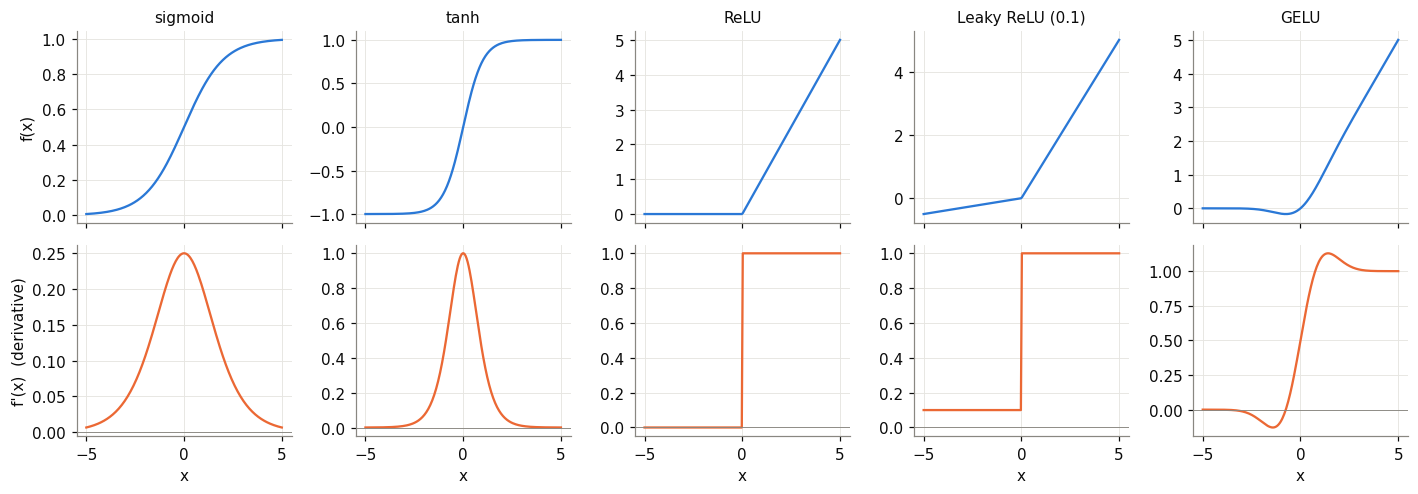

best case, 10 layers:  sigmoid 0.25**10 = 9.54e-07    ReLU 1**10 = 1


In [15]:
# 活性化関数と、その微分。微分の式を、PyTorch の自動微分と、数値微分（重みでなく入力を少し動かす）の両方と突き合わせる
sig = lambda v: 1 / (1 + np.exp(-v))
ACT = {   # 名前: (PyTorch の関数, 微分の式)
    "sigmoid": (torch.sigmoid, lambda v: sig(v) * (1 - sig(v))),
    "tanh": (torch.tanh, lambda v: 1 - np.tanh(v) ** 2),
    "ReLU": (torch.relu, lambda v: (v > 0).astype(float)),
    "Leaky ReLU (0.1)": (lambda t_: nn.functional.leaky_relu(t_, 0.1), lambda v: np.where(v > 0, 1.0, 0.1)),
    "GELU": (nn.functional.gelu, lambda v: stats.norm.cdf(v) + v * stats.norm.pdf(v)),
}
vv = np.linspace(-5, 5, 200)                                     # 200 点なので 0 を含まない（ReLU は 0 で微分できない）
fig, axs = plt.subplots(2, 5, figsize=(13, 4.6), sharex=True)
for k, (name, (f_, d_)) in enumerate(ACT.items()):
    xt = torch.tensor(vv, dtype=torch.float64, requires_grad=True)
    f_(xt).sum().backward()                                      # 自動微分。sum にすると、各点の微分がそのまま xt.grad に入る
    e = 1e-6
    with torch.no_grad():
        num = ((f_(torch.tensor(vv + e)) - f_(torch.tensor(vv - e))) / (2 * e)).numpy()     # 数値微分（中心差分。e = 1e-6 は人が決めた値）
    d_auto, d_form = xt.grad.numpy(), d_(vv)
    print(f"{name:18s} max|formula - autograd| = {np.abs(d_form - d_auto).max():.1e}   max|formula - numeric| = {np.abs(d_form - num).max():.1e}   max derivative = {d_form.max():.3f}")
    assert np.abs(d_form - d_auto).max() < 1e-8 and np.abs(d_form - num).max() < 1e-5, name
    axs[0, k].plot(vv, f_(torch.tensor(vv)).numpy(), color=BLUE); axs[0, k].set_title(name, fontsize=10)
    axs[1, k].plot(vv, d_form, color=ORANGE); axs[1, k].axhline(0, color=MUTED, lw=0.6)
    axs[1, k].set_xlabel("x")
axs[0, 0].set_ylabel("f(x)"); axs[1, 0].set_ylabel("f'(x)  (derivative)")
plt.tight_layout(); plt.show()
print("best case, 10 layers:  sigmoid 0.25**10 =", f"{0.25 ** 10:.2e}", "   ReLU 1**10 =", 1 ** 10)

### 出力の関数は、モデルの役割で変わる

隠れ層の活性化関数は、ほとんど ReLU 系で足ります。**一方、「出力の関数」と「損失」は、モデルが何を答えるかで決まります**。**出力層が最後に出す生の数を、「ロジット」と呼びます**（確率にする前の数。ロジットは関数の名前ではなく、**出力の呼び名**です）。

| 役割 | 出力（ロジットのあと） | 損失 | PyTorch（ロジットを渡す） |
|---|---|---|---|
| **回帰**（値を当てる） | **そのまま**（恒等） | 二乗誤差（MSE）、絶対誤差（MAE） | `nn.MSELoss` |
| **二値分類**（この回の悪性／良性） | **シグモイド**（0〜1 の確率 1 つ） | **二値クロスエントロピー（BCE）** | `nn.BCEWithLogitsLoss` |
| **多クラス分類**（どれか 1 つ。正常・良性・悪性など） | **ソフトマックス**（全クラスの確率の合計が 1） | **クロスエントロピー** | `nn.CrossEntropyLoss` |
| **多ラベル分類**（複数の所見が、同時にあってよい） | **クラスごとにシグモイド**（確率の合計は 1 にならない） | クラスごとの BCE | `nn.BCEWithLogitsLoss` |
| **セグメンテーション** | **画素ごとに**シグモイド（1 クラス）またはソフトマックス（多クラス） | 画素ごとの CE、Dice 損失（7 節） | 同上 |
| **LLM** | **語彙の全部**（数万語）に対するソフトマックス | 次の単語の CE | `nn.CrossEntropyLoss` |

**見分け方**: **答えが「複数のうち 1 つ」ならソフトマックス、「それぞれ あり・なし」ならシグモイド、「数値」なら恒等**です。

<details open data-ig="losses" style="margin:14px 0">
  <summary style="cursor:pointer;font-weight:700">図で見る — 損失関数 6 つ — 「外れるほど大きい」の見え方（クリックで閉じる・開く）</summary>
  <div style="overflow-x:auto;margin-top:10px;padding:8px;border:1px solid rgba(128,128,128,0.45);border-radius:6px">
<svg viewBox="0 0 818 452" width="100%" style="min-width:620px;display:block" role="img" aria-label="損失関数 6 つを、「予測が外れるほど損失が大きい」の見え方で並べたパネル">
  <rect x="0.0" y="0.0" width="266.0" height="200.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">回帰</text>
  <text x="10" y="38" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">予測が正解から離れるほど、二乗で増える</text>
  <rect x="18.0" y="50.0" width="230.0" height="100.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 18.0 50.0 L 20.9 54.9 L 23.8 59.8 L 26.6 64.4 L 29.5 69.0 L 32.4 73.4 L 35.2 77.8 L 38.1 81.9 L 41.0 86.0 L 43.9 89.9 L 46.8 93.8 L 49.6 97.4 L 52.5 101.0 L 55.4 104.4 L 58.2 107.8 L 61.1 110.9 L 64.0 114.0 L 66.9 116.9 L 69.8 119.8 L 72.6 122.4 L 75.5 125.0 L 78.4 127.4 L 81.2 129.8 L 84.1 131.9 L 87.0 134.0 L 89.9 135.9 L 92.8 137.8 L 95.6 139.4 L 98.5 141.0 L 101.4 142.4 L 104.2 143.8 L 107.1 144.9 L 110.0 146.0 L 112.9 146.9 L 115.8 147.8 L 118.6 148.4 L 121.5 149.0 L 124.4 149.4 L 127.2 149.8 L 130.1 149.9 L 133.0 150.0 L 135.9 149.9 L 138.8 149.8 L 141.6 149.4 L 144.5 149.0 L 147.4 148.4 L 150.2 147.8 L 153.1 146.9 L 156.0 146.0 L 158.9 144.9 L 161.8 143.8 L 164.6 142.4 L 167.5 141.0 L 170.4 139.4 L 173.2 137.8 L 176.1 135.9 L 179.0 134.0 L 181.9 131.9 L 184.8 129.8 L 187.6 127.4 L 190.5 125.0 L 193.4 122.4 L 196.2 119.8 L 199.1 116.9 L 202.0 114.0 L 204.9 110.9 L 207.8 107.8 L 210.6 104.4 L 213.5 101.0 L 216.4 97.4 L 219.2 93.8 L 222.1 89.9 L 225.0 86.0 L 227.9 81.9 L 230.8 77.7 L 233.6 73.4 L 236.5 69.0 L 239.4 64.4 L 242.2 59.8 L 245.1 54.9 L 248.0 50.0" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <line x1="133.0" y1="50.0" x2="133.0" y2="150.0" stroke="currentColor" stroke-width="1.0" stroke-dasharray="3 3" stroke-opacity="0.7"/>
  <circle cx="202.0" cy="114.0" r="5.0" fill="#D9782F" fill-opacity="1.0"/>
  <text x="133" y="164" font-size="10" text-anchor="middle" font-weight="400" fill="currentColor">正解 2</text>
  <text x="202" y="164" font-size="10" text-anchor="middle" font-weight="700" fill="#D9782F">予測 3.2</text>
  <text x="10" y="186" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">損失（二乗誤差）= (3.2 − 2)² = 1.44</text>
  <rect x="276.0" y="0.0" width="266.0" height="200.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="286" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">二値分類（BCE）</text>
  <text x="286" y="38" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">正解に自信を持って外すほど、急に大きい</text>
  <rect x="294.0" y="50.0" width="230.0" height="88.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <path d="M 294.0 51.9 L 296.9 62.3 L 299.8 69.3 L 302.6 74.6 L 305.5 78.9 L 308.4 82.4 L 311.2 85.5 L 314.1 88.2 L 317.0 90.6 L 319.9 92.8 L 322.8 94.7 L 325.6 96.6 L 328.5 98.2 L 331.4 99.8 L 334.2 101.2 L 337.1 102.6 L 340.0 103.9 L 342.9 105.1 L 345.8 106.2 L 348.6 107.3 L 351.5 108.4 L 354.4 109.4 L 357.2 110.3 L 360.1 111.2 L 363.0 112.1 L 365.9 112.9 L 368.8 113.7 L 371.6 114.5 L 374.5 115.3 L 377.4 116.0 L 380.2 116.7 L 383.1 117.4 L 386.0 118.1 L 388.9 118.7 L 391.8 119.3 L 394.6 119.9 L 397.5 120.5 L 400.4 121.1 L 403.2 121.7 L 406.1 122.2 L 409.0 122.8 L 411.9 123.3 L 414.8 123.8 L 417.6 124.3 L 420.5 124.8 L 423.4 125.2 L 426.2 125.7 L 429.1 126.2 L 432.0 126.6 L 434.9 127.1 L 437.8 127.5 L 440.6 127.9 L 443.5 128.3 L 446.4 128.7 L 449.2 129.1 L 452.1 129.5 L 455.0 129.9 L 457.9 130.3 L 460.8 130.7 L 463.6 131.0 L 466.5 131.4 L 469.4 131.7 L 472.2 132.1 L 475.1 132.4 L 478.0 132.8 L 480.9 133.1 L 483.8 133.4 L 486.6 133.7 L 489.5 134.1 L 492.4 134.4 L 495.2 134.7 L 498.1 135.0 L 501.0 135.3 L 503.9 135.6 L 506.8 135.9 L 509.6 136.2 L 512.5 136.5 L 515.4 136.7 L 518.2 137.0 L 521.1 137.3 L 524.0 137.6" fill="none" stroke="#2E9E94" stroke-width="2.2"/>
  <path d="M 294.0 137.6 L 296.9 137.3 L 299.8 137.0 L 302.6 136.7 L 305.5 136.5 L 308.4 136.2 L 311.2 135.9 L 314.1 135.6 L 317.0 135.3 L 319.9 135.0 L 322.8 134.7 L 325.6 134.4 L 328.5 134.1 L 331.4 133.7 L 334.2 133.4 L 337.1 133.1 L 340.0 132.8 L 342.9 132.4 L 345.8 132.1 L 348.6 131.7 L 351.5 131.4 L 354.4 131.0 L 357.2 130.7 L 360.1 130.3 L 363.0 129.9 L 365.9 129.5 L 368.8 129.1 L 371.6 128.7 L 374.5 128.3 L 377.4 127.9 L 380.2 127.5 L 383.1 127.1 L 386.0 126.6 L 388.9 126.2 L 391.8 125.7 L 394.6 125.2 L 397.5 124.8 L 400.4 124.3 L 403.2 123.8 L 406.1 123.3 L 409.0 122.8 L 411.9 122.2 L 414.8 121.7 L 417.6 121.1 L 420.5 120.5 L 423.4 119.9 L 426.2 119.3 L 429.1 118.7 L 432.0 118.1 L 434.9 117.4 L 437.8 116.7 L 440.6 116.0 L 443.5 115.3 L 446.4 114.5 L 449.2 113.7 L 452.1 112.9 L 455.0 112.1 L 457.9 111.2 L 460.8 110.3 L 463.6 109.4 L 466.5 108.4 L 469.4 107.3 L 472.2 106.2 L 475.1 105.1 L 478.0 103.9 L 480.9 102.6 L 483.8 101.2 L 486.6 99.8 L 489.5 98.2 L 492.4 96.6 L 495.2 94.7 L 498.1 92.8 L 501.0 90.6 L 503.9 88.2 L 506.8 85.5 L 509.6 82.4 L 512.5 78.9 L 515.4 74.6 L 518.2 69.3 L 521.1 62.3 L 524.0 51.9" fill="none" stroke="#D9782F" stroke-width="2.0" stroke-dasharray="4 3"/>
  <circle cx="409.0" cy="122.8" r="4.5" fill="currentColor" fill-opacity="1.0"/>
  <text x="417" y="115" font-size="10" text-anchor="start" font-weight="700" fill="currentColor">p=0.5 → ln 2 = 0.693</text>
  <text x="294" y="152" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">p = 0</text>
  <text x="524" y="152" font-size="10" text-anchor="end" font-weight="400" fill="currentColor">p = 1</text>
  <text x="286" y="172" font-size="10.5" text-anchor="start" font-weight="700" fill="#2E9E94">実線: 正解が 1 のとき −log p</text>
  <text x="286" y="188" font-size="10.5" text-anchor="start" font-weight="700" fill="#D9782F">点線: 正解が 0 のとき −log(1 − p)</text>
  <rect x="552.0" y="0.0" width="266.0" height="200.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="562" y="22" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">多クラス（クロスエントロピー）</text>
  <text x="562" y="38" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">どれか 1 つ。正解の確率が小さいほど大きい</text>
  <text x="564" y="70" font-size="11" text-anchor="start" font-weight="400" fill="currentColor">正常</text>
  <rect x="608.0" y="56.0" width="138.3" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <text x="750" y="70" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">0.79</text>
  <text x="564" y="100" font-size="11" text-anchor="start" font-weight="400" fill="currentColor">良性</text>
  <rect x="608.0" y="86.0" width="30.9" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <text x="643" y="100" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">0.18</text>
  <text x="564" y="130" font-size="11" text-anchor="start" font-weight="700" fill="currentColor">悪性</text>
  <rect x="608.0" y="116.0" width="6.9" height="20.0" rx="2" fill="#D9782F" fill-opacity="0.55"/>
  <text x="619" y="130" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">0.04</text>
  <text x="562" y="160" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">正解は「悪性」。確率 0.04</text>
  <text x="562" y="180" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">損失 = −log 0.039 = 3.241</text>
  <rect x="0.0" y="210.0" width="266.0" height="200.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="10" y="232" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">多ラベル（クラスごとの BCE）</text>
  <text x="10" y="248" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">それぞれ あり・なし。合計 1 にはならない</text>
  <text x="12" y="280" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">骨折（正解 あり）</text>
  <rect x="118.0" y="266.0" width="81.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <rect x="118.0" y="266.0" width="90.0" height="20.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <text x="214" y="280" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">0.11</text>
  <text x="12" y="310" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">気胸（正解 なし）</text>
  <rect x="118.0" y="296.0" width="18.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <rect x="118.0" y="296.0" width="90.0" height="20.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <text x="214" y="310" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">0.22</text>
  <text x="12" y="340" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">胸水（正解 あり）</text>
  <rect x="118.0" y="326.0" width="54.0" height="20.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <rect x="118.0" y="326.0" width="90.0" height="20.0" rx="2" fill="none" stroke="rgba(128,128,128,0.45)" stroke-width="0.8"/>
  <text x="214" y="340" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">0.51</text>
  <text x="10" y="370" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">棒 = そのラベルが「あり」の確率</text>
  <text x="10" y="390" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">損失 = 3 つの平均 = 0.280</text>
  <rect x="276.0" y="210.0" width="266.0" height="200.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="286" y="232" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">セグメンテーション（Dice 損失）</text>
  <text x="286" y="248" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">正解と予測の重なりが小さいほど大きい</text>
  <rect x="300.0" y="264.0" width="76.8" height="76.8" rx="2" fill="#2E9E94" fill-opacity="0.25" stroke="#2E9E94" stroke-width="1.6"/>
  <rect x="328.8" y="264.0" width="76.8" height="76.8" rx="2" fill="#D9782F" fill-opacity="0.25" stroke="#D9782F" stroke-width="1.6"/>
  <text x="304" y="354" font-size="10" text-anchor="start" font-weight="700" fill="#2E9E94">青緑 = 正解（8×8）</text>
  <text x="304" y="368" font-size="10" text-anchor="start" font-weight="700" fill="#D9782F">橙 = 予測（3 画素ずれ）</text>
  <text x="426" y="290" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">重なり 40 画素</text>
  <text x="426" y="308" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">Dice = 2×40 / (64+64)</text>
  <text x="426" y="324" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">= 0.625</text>
  <text x="286" y="396" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">損失 = 1 − Dice = 0.375</text>
  <rect x="552.0" y="210.0" width="266.0" height="200.0" rx="6" fill="currentColor" fill-opacity="0.05" stroke="rgba(128,128,128,0.45)" stroke-width="1"/>
  <text x="562" y="232" font-size="13.5" text-anchor="start" font-weight="700" fill="currentColor">言語モデル（次の単語）</text>
  <text x="562" y="248" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor" fill-opacity="0.9">語彙の全部に確率を割り当て、クロスエントロピー</text>
  <text x="564" y="272" font-size="11" text-anchor="start" font-weight="400" fill="currentColor">「今日は天気が」の次は？</text>
  <text x="564" y="296" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">良い</text>
  <rect x="622.0" y="282.0" width="48.0" height="15.0" rx="2" fill="#D9782F" fill-opacity="0.55"/>
  <text x="674" y="294" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">0.30</text>
  <text x="564" y="316" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">悪い</text>
  <rect x="622.0" y="302.0" width="16.0" height="15.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <text x="642" y="314" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">0.10</text>
  <text x="564" y="336" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">晴れ</text>
  <rect x="622.0" y="322.0" width="72.0" height="15.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <text x="698" y="334" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">0.45</text>
  <text x="564" y="356" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">その他</text>
  <rect x="622.0" y="342.0" width="24.0" height="15.0" rx="2" fill="#2E9E94" fill-opacity="0.55"/>
  <text x="650" y="354" font-size="10" text-anchor="start" font-weight="400" fill="currentColor">0.15</text>
  <text x="562" y="386" font-size="10.5" text-anchor="start" font-weight="400" fill="currentColor">正解は「良い」（確率 0.30）</text>
  <text x="562" y="402" font-size="10.5" text-anchor="start" font-weight="700" fill="currentColor">損失 = −log 0.30 = 1.20</text>
  <text x="4" y="434" font-size="11" text-anchor="start" font-weight="400" fill="currentColor">どの損失も、「予測が正解から外れるほど、大きくなる」形です。値は、仕組みを見るための例です（実データの結果ではありません）。</text>
</svg>
  </div>
  <div style="margin-top:8px;font-size:0.85em"><strong>概念図</strong>です。式から描いた曲線と、例の数値（多クラスの 3.241 は、5 節の出力と同じ）を使っています。</div>
</details>

**PyTorch の損失は、確率ではなく「ロジット」を受け取る版を使います**（`BCEWithLogitsLoss`、`CrossEntropyLoss`）。**中で、シグモイド・ソフトマックスと対数を、数値的に安全な形で一度に計算する**ためです。**確率にしてから `BCELoss` に渡すと、極端な値で、黙って違う値になります**（下で確かめます）。

softmax: [0.7856 0.1753 0.0391]  sum = 1.0
cross entropy: by hand 3.241311   torch 3.241311
2-class softmax 0.785835   sigmoid 0.785835
BCEWithLogitsLoss (logit)       : 200.0
BCELoss (after sigmoid)         : 100.0  <- clipped, silently wrong


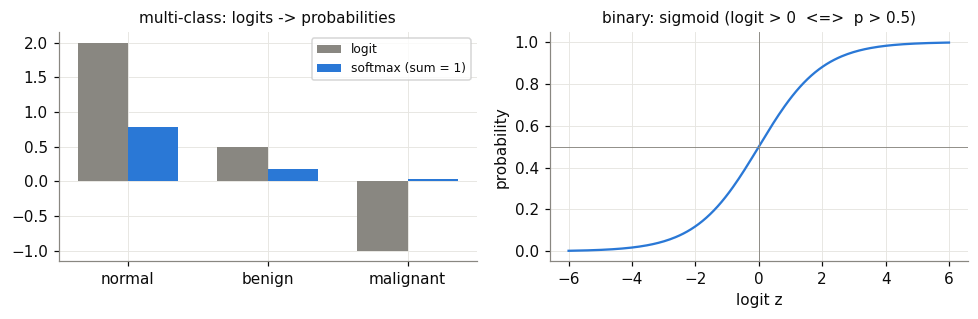

In [16]:
# 多クラス: ソフトマックスとクロスエントロピーを手で書き、PyTorch と一致するか確かめる
lg = np.array([2.0, 0.5, -1.0])                                    # 3 クラスのロジット（例: 正常・良性・悪性）。値は、仕組みを見るために人が決めた
sm = np.exp(lg) / np.exp(lg).sum()                                 # ソフトマックス: 全部を exp して、合計で割る（合計 1 の確率になる）
true_cls = 2                                                       # 正解は「悪性」（番号 2）とする
ce_hand = -np.log(sm[true_cls])                                    # クロスエントロピー: 正解のクラスの確率の、−log
ce_torch = nn.CrossEntropyLoss()(torch.tensor(lg[None, :], dtype=torch.float32), torch.tensor([true_cls])).item()
print("softmax:", np.round(sm, 4), " sum =", round(float(sm.sum()), 6))
print(f"cross entropy: by hand {ce_hand:.6f}   torch {ce_torch:.6f}")
assert abs(ce_hand - ce_torch) < 1e-5
# 二値: 「2 クラスのソフトマックス」と「シグモイド」は同じ（ロジットの差が、シグモイドの入力になる）
z_bin = 1.3
two = np.exp([z_bin, 0.0]) / np.exp([z_bin, 0.0]).sum()
print(f"2-class softmax {two[0]:.6f}   sigmoid {float(sig(z_bin)):.6f}")
assert abs(two[0] - sig(z_bin)) < 1e-12
# 確率にしてから BCELoss に渡すと危ない例: ロジット 200 で、正解が 0（大きく外した）のとき、損失は 200 のはず
zb, yb = torch.tensor([200.0]), torch.tensor([0.0])
print("BCEWithLogitsLoss (logit)       :", round(nn.BCEWithLogitsLoss()(zb, yb).item(), 3))
print("BCELoss (after sigmoid)         :", round(nn.BCELoss()(torch.sigmoid(zb), yb).item(), 3), " <- clipped, silently wrong")
# 活性化の図: ソフトマックス（左）とシグモイド（右）
fig, axs = plt.subplots(1, 2, figsize=(9, 3.0))
kk = np.arange(3); axs[0].bar(kk - 0.18, lg, width=0.36, color=MUTED, label="logit"); axs[0].bar(kk + 0.18, sm, width=0.36, color=BLUE, label="softmax (sum = 1)")
axs[0].set_xticks(kk); axs[0].set_xticklabels(["normal", "benign", "malignant"]); axs[0].legend(fontsize=8); axs[0].set_title("multi-class: logits -> probabilities", fontsize=10)
zz_ = np.linspace(-6, 6, 200); axs[1].plot(zz_, sig(zz_), color=BLUE); axs[1].axhline(0.5, color=MUTED, lw=0.6); axs[1].axvline(0, color=MUTED, lw=0.6)
axs[1].set_xlabel("logit z"); axs[1].set_ylabel("probability"); axs[1].set_title("binary: sigmoid (logit > 0  <=>  p > 0.5)", fontsize=10)
plt.tight_layout(); plt.show()

**読み取り**: ソフトマックスの合計は 1 で、**手で書いたクロスエントロピーは、PyTorch の `CrossEntropyLoss` と一致**します。**2 クラスのソフトマックスは、シグモイドと同じ**です（二値は、確率 1 つで足りる）。**ロジット 200 で正解が 0 のとき、`BCEWithLogitsLoss` は 200 を返しますが、確率にしてから `BCELoss` に渡すと、損失が 100 で頭打ちになります**（対数の下限を切っているため）。**エラーは出ません。** この回の 4〜6 節は、**ロジットを渡す版**を使っています。

### 参考 — モデルの姿で、訓練は変わる（解説のみ。コードは実行しません）

**「損失を測り、勾配を求め、重みを動かす」は、全部同じ**です。**変わるのは、何を損失にするか、何を何と比べるか、データの出し方**です。

| モデル | 損失 | 訓練データ | 訓練の特徴 | 評価 |
|---|---|---|---|---|
| DNN・CNN（分類） | クロスエントロピー | （画像、ラベル）の対 | 4〜6 節のとおり | 正解率・AUC など（第7回） |
| U-Net（セグメンテーション） | **Dice 損失**やクロスエントロピーを、**画素ごと**に | （画像、マスク）の対 | **背景が大半**で、「何も塗らない」予測でも画素の正解率が高い（第7回 8-1）。損失に Dice を使うのは、この対策 | Dice・IoU |
| GAN | **作る側の損失**と**見破る側の損失**（2 つ） | 本物の画像（ラベル不要） | **2 つを交互に更新**。**損失が下がっても、画像が良くなったとは限らない** | **損失では測れない**（人の目、別の指標） |
| LLM | **次の単語の、クロスエントロピー** | 巨大な文章（ラベルは、次の単語そのもの） | **「次を当てる」で事前学習**し、そのあと人の好みなどで調整 | 困惑度（perplexity）、課題別の試験 |
| VLM（CLIP 型） | **画像と文章の対応を当てる**（対照学習） | （画像、説明文）の対 | バッチの中で、**正しい組み合わせの類似度を上げ、他を下げる** | 零ショットの分類、検索 |
| エージェント | モデルの訓練ではなく、**モデルを使う外側のループ**が中心。行動の訓練には、強化学習などを使うことがある | 行動の記録、報酬 | **評価が難しい**（結果が長い手順の末に決まる） | 課題の達成率 |

**学習していないモデルの損失は、答えが当てずっぽうのときの値**になり、これは**式で出せます**。2 値分類で、確率 0.5 でずっと答える（ロジット 0）なら **ln 2 ≈ 0.693**、10 クラスなら **ln 10 ≈ 2.303**、語彙が 1000 語の言語モデルなら **ln 1000 ≈ 6.908**（困惑度 = exp(損失) = 1000 で、語彙の数と同じ。「次の単語を、何通りから迷っているか」と読めます）。**訓練の最初に、損失がこの値からかけ離れていたら、初期化かデータの渡し方が間違っています**（確認に使えます）。

**U-Net の注意**: 1024 画素のうち 64 画素（約 6%）が病変のとき、**何も塗らない予測でも、画素の正解率は 960/1024 = 0.9375 と高い**のに、**Dice 損失は 1（最悪）**です。**第7回の「何も塗らない予測」と同じ**で、**セグメンテーションで Dice を損失に使う理由**です。

## 8. 説明可能性 — GradCAM

画像の分類モデルは、**なぜ「肺炎」と答えたか**を、重みを見ても読めません。**GradCAM**（Selvaraju ほか. ICCV 2017:618-626）は、**最後の畳み込み層の出力のうち、答えに効いた場所**を、画像に重ねる方法です。

1. 最後の畳み込み層の出力 A（チャンネルごとの、小さな画像）を保存する
2. **「肺炎」のロジットを、A で微分**し（誤差逆伝播と同じ仕組み）、チャンネルごとに平均して**重み α**にする
3. **Σ α·A** を作り、負の部分を 0 にして（ReLU）、画像の大きさに拡大する

**使うデータ: PneumoniaMNIST**（MedMNIST v2。Yang ほか. Sci Data 2023;10:41、CC BY 4.0）。**元は小児の胸部 X 線**（Kermany ほか. Cell 2018;172:1122-1131）で、**肺炎／正常**の 2 クラス。**64×64 画素**の版を使います。

**データについて、確認できたこと・できなかったこと**（2026-10-14）:
- 確認できた: MedMNIST の説明は、「5,856 枚の小児の胸部 X 線（元のデータ）を、中央を切り出して縮小」「元の訓練用を 9:1 に分けて訓練用・検証用にし、元の検証用をテスト用にした」。**元のデータは、画像の名前に患者の ID を持ち、訓練用とテスト用は独立した患者に分けてある**（元データの公開ページの説明）
- **確認できなかった**: **収集期間、撮影装置、撮影の条件**（MedMNIST の説明・元データの公開ページに記載なし。**元論文の本文は、取得できず未確認**）。**MedMNIST の「訓練用と検証用」が、患者単位で分けてあるか**（**不明**。画像単位なら、同じ患者が両方に入り、検証の成績が高く出る。第7回 9 節）
- **クラスの割合が、訓練用とテスト用で違う**（下で数える）。**検証用の成績が、そのまま将来の成績ではない**

In [17]:
# PneumoniaMNIST を読む。初回は約 20 MB のダウンロードがある（ネット接続が必要。この PC では 1〜4 分かかり、その間は何も表示されない。失敗したら、課題の注意を読む）
import subprocess, sys
try:
    import medmnist
except ImportError:                                               # 入っていなければ、ここで入れる（数十秒。Colab に入っているかは未確認）
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist"], check=True)
from medmnist import PneumoniaMNIST
import os
os.makedirs("mm", exist_ok=True)                                  # 保存先のフォルダ（medmnist は、先に作っておかないとエラーになる）
import contextlib, io
def load_img(split):
    for attempt in range(3):                                                   # ダウンロードが途中で切れると、ファイルが壊れて RuntimeError になる（実際に起きた）。3 回までやり直す（3 は人が決めた値）
        try:
            with contextlib.redirect_stderr(io.StringIO()):                    # ダウンロードの進み具合の表示（長くなる）を、画面に出さない
                d = PneumoniaMNIST(split=split, download=True, size=64, root="mm")     # size=64: 64×64 画素の版
            break
        except RuntimeError:
            f = os.path.join("mm", "pneumoniamnist_64.npz")
            if os.path.exists(f): os.remove(f)                                 # 壊れたファイルを消してから、やり直す
            if attempt == 2: raise
    return torch.tensor(d.imgs, dtype=torch.float32).unsqueeze(1) / 255, torch.tensor(d.labels.ravel(), dtype=torch.float32)     # 0〜1 に直し、(N,1,64,64) にする
(Itr, jtr), (Iva, jva), (Ite, jte) = load_img("train"), load_img("val"), load_img("test")
rows = [[s, len(j), int(j.sum()), int((j == 0).sum()), round(float(j.mean()), 3)] for s, j in [("train", jtr), ("val", jva), ("test", jte)]]
print(pd.DataFrame(rows, columns=["split", "images", "pneumonia", "normal", "pneumonia fraction"]).to_string(index=False))
print("image tensor:", tuple(Itr.shape), "pixel range:", float(Itr.min()), "-", float(Itr.max()))

split  images  pneumonia  normal  pneumonia fraction
train    4708       3494    1214               0.742
  val     524        389     135               0.742
 test     624        390     234               0.625
image tensor: (4708, 1, 64, 64) pixel range: 0.0 - 1.0


In [ ]:
# 小さな CNN（畳み込み 3 層＋平均＋全結合）。最後の畳み込み層の出力を、GradCAM で使う
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(                                     # 畳み込み層（3×3 の窓）と ReLU と縮小（max pooling）
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 64 → 32 画素
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32 → 16 画素
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU())                    # 16×16 の地図が 32 枚（最後の畳み込み層）
        self.head = nn.Linear(32, 1)                                       # 地図ごとの平均 32 個 → ロジット 1 個
    def forward(self, x):
        return self.head(self.features(x).mean(dim=(2, 3))).squeeze(1)     # 地図を平均（global average pooling）してから、全結合

def eval_img(m, I, j):
    m.eval()
    with torch.no_grad(): z = torch.cat([m(I[i:i + 512]) for i in range(0, len(I), 512)]).numpy()
    return ((z > 0).astype(int) == j.numpy()).mean(), roc_auc_score(j.numpy(), z), z

torch.manual_seed(0)
cnn = SmallCNN(); print("parameters:", sum(p.numel() for p in cnn.parameters()))
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3); L = nn.BCEWithLogitsLoss()      # 学習率 0.001、エポック 10、バッチ 64 は人が決めた値
hist_cnn, best_cnn = [], (1e9, None, -1)
for ep in range(10):
    cnn.train(); order = torch.randperm(len(Itr))
    for i in range(0, len(order), 64):
        idx = order[i:i + 64]; opt.zero_grad(); L(cnn(Itr[idx]), jtr[idx]).backward(); opt.step()
    a_tr, _, _ = eval_img(cnn, Itr, jtr); a_va, auc_va, zv = eval_img(cnn, Iva, jva)
    lv = L(torch.tensor(zv), jva).item(); hist_cnn.append((a_tr, a_va, auc_va, lv))
    if lv < best_cnn[0]: best_cnn = (lv, copy.deepcopy(cnn.state_dict()), ep)       # 検証用の損失が最小の重み
    print(f"epoch {ep + 1}: train acc {a_tr:.3f}  val acc {a_va:.3f}  val AUC {auc_va:.3f}  val loss {lv:.3f}")
cnn.load_state_dict(best_cnn[1]); cnn.eval()
print("best epoch by validation loss:", best_cnn[2] + 1)

parameters: 5921


epoch 1: train acc 0.742  val acc 0.742  val AUC 0.661  val loss 0.556


epoch 2: train acc 0.720  val acc 0.712  val AUC 0.728  val loss 0.531


epoch 3: train acc 0.729  val acc 0.729  val AUC 0.760  val loss 0.495


epoch 4: train acc 0.743  val acc 0.746  val AUC 0.785  val loss 0.493


epoch 5: train acc 0.812  val acc 0.805  val AUC 0.872  val loss 0.410


epoch 6: train acc 0.889  val acc 0.872  val AUC 0.931  val loss 0.338


epoch 7: train acc 0.904  val acc 0.895  val AUC 0.943  val loss 0.296


epoch 8: train acc 0.908  val acc 0.895  val AUC 0.950  val loss 0.279


epoch 9: train acc 0.911  val acc 0.889  val AUC 0.953  val loss 0.263


epoch 10: train acc 0.909  val acc 0.889  val AUC 0.953  val loss 0.247
best epoch by validation loss: 10


In [ ]:
# テスト用に、1 回だけ出す。クラスの割合が違うので、正解率だけでなく感度・特異度・AUC も見る（第7回 8 節）
a_te, auc_te, zte_img = eval_img(cnn, Ite, jte)
tn, fp, fn, tp = confusion_matrix(jte.numpy(), (zte_img > 0).astype(int)).ravel()
print(f"test: accuracy {a_te:.3f}  sensitivity {tp}/{tp + fn} = {tp / (tp + fn):.3f}  specificity {tn}/{tn + fp} = {tn / (tn + fp):.3f}  AUC {auc_te:.3f}")
print(f"always answering 'pneumonia' on the test set: accuracy {float(jte.mean()):.3f}")

test: accuracy 0.851  sensitivity 374/390 = 0.959  specificity 157/234 = 0.671  AUC 0.927
always answering 'pneumonia' on the test set: accuracy 0.625


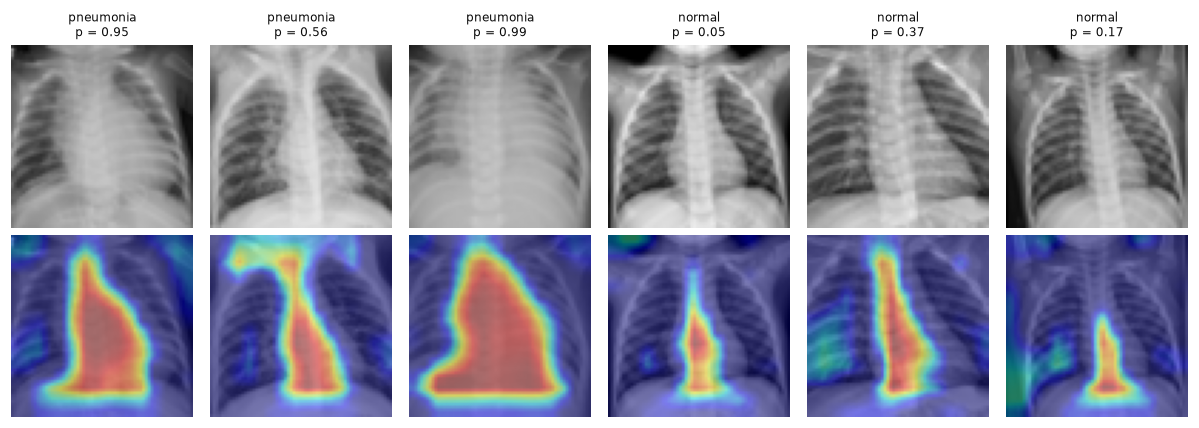

In [ ]:
# GradCAM を、自分で書く。フックで、最後の畳み込み層の出力と、その勾配を取り出す
def grad_cam(model, x):
    store = {}
    layer = model.features[-1]                                             # 最後の ReLU の出力（16×16 の地図 32 枚）
    h1 = layer.register_forward_hook(lambda mod, i, o: store.update(A=o))                 # 順伝播のとき、出力 A を保存
    model.zero_grad()
    z = model(x.unsqueeze(0))                                              # 1 枚の画像を、(1,1,64,64) にして入れる
    A = store["A"]; h1.remove()
    g = torch.autograd.grad(z.sum(), A)[0]                                 # 「肺炎」のロジットを A で微分（誤差逆伝播と同じ仕組み）
    alpha = g.mean(dim=(2, 3), keepdim=True)                               # 地図ごとの重み α = 勾配の平均
    cam = torch.relu((alpha * A).sum(dim=1, keepdim=True))                 # Σ α·A の、負の部分を 0 に
    cam = nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]     # 画像の大きさ（64×64）に拡大
    cam = cam / cam.max() if cam.max() > 0 else cam                        # 0〜1 に正規化（図にするため）
    return cam.detach(), z.item()

# 正しく分類できたテスト画像を、肺炎 3 枚・正常 3 枚選ぶ（先頭から順に。人が決めた選び方。都合のよい画像を選ばないため）
ok = ((zte_img > 0).astype(int) == jte.numpy())
pick = [int(i) for i in np.where(ok & (jte.numpy() == 1))[0][:3]] + [int(i) for i in np.where(ok & (jte.numpy() == 0))[0][:3]]
# 図の読み方: 上の段は元の画像、下の段は、GradCAM（赤いほど「肺炎」の答えに効いた場所）を重ねたもの。タイトルは、正解と、モデルが答えた「肺炎の確率」。
fig, axs = plt.subplots(2, 6, figsize=(11, 4))
for k, i in enumerate(pick):
    cam, z = grad_cam(cnn, Ite[i])
    axs[0, k].imshow(Ite[i, 0], cmap="gray", vmin=0, vmax=1)
    axs[1, k].imshow(Ite[i, 0], cmap="gray", vmin=0, vmax=1); axs[1, k].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axs[0, k].set_title(("pneumonia" if jte[i] == 1 else "normal") + f"\np = {1 / (1 + np.exp(-z)):.2f}", fontsize=8)
    for a in axs[:, k]: a.axis("off"); a.grid(False)
plt.tight_layout(); plt.show()

**読み取り**: **データ**: 訓練用は 4,708 枚で、**肺炎が 74%**。検証用も 74%。**テスト用は 624 枚で、肺炎が 62.5%**（訓練用と割合が違います）。

**CNN**（パラメータ 5,921 個）の訓練は、10 エポックで、**検証用の損失が下がり続けています**（0.556 → 0.247）。**最後のエポックが最良で、まだ学習の途中です**（エポックを増やせば、さらに上がる可能性が高い。ここでは、時間の都合で 10 エポックにしました）。

**テスト用（1 回）**: **正解率 0.851、感度 374/390 = 0.959、特異度 157/234 = 0.671、AUC 0.927**。**「全部肺炎と答える」でも正解率は 0.625** なので、それよりは良い。ただし**特異度が 0.671 と低く、正常の約 3 分の 1 を肺炎と答えています**。**検証用の AUC（0.953）より、テスト用（0.927）が低い**のは、**訓練・検証と、テスト用で、クラスの割合も違う**ことと合う話ですが、**原因は、この実験からは特定できません**。

**GradCAM の図**: 地図は、**どの画像でも、胸の中央（縦隔のあたり）に赤く出ます**。**肺炎（左の 3 枚）は、中央から片側の肺野にかけて広く、正常（右の 3 枚）は、中央の細い帯**です。**肺の端や、肺野の細かい所見の場所は、あまり赤くなりません**。

**この図から言えること・言えないこと**: **言える**: このモデルは、**胸の中央を中心に見て**答えを出している（次の削除テストで確かめます）。**言えない**: **その場所が、肺炎の所見のある場所か**。それは、**放射線科医が判断すること**で、この図は証拠になりません。**別の胸部 X 線のデータでは、病変でなく、画像の隅の文字や撮影装置の違いを手がかりにしていた例が報告されています**（Zech ほか. PLOS Med 2018;15:e1002683、DeGrave ほか. Nat Mach Intell 2021;3:610-619）。**地図が「それらしい」ことは、モデルが正しい理由で答えている証拠になりません**。

### この地図を、信じてよいか — 2 つの確かめ

**地図が「それらしく」見えることは、証拠ではありません。** 次の 2 つで確かめます。

1. **削除テスト**: **地図が赤い所を隠す**と、「肺炎」の答えは弱まるか。**同じ面積を、でたらめな場所で隠した場合と比べます**（地図が本当に効いた場所を指しているなら、地図で隠したほうが、大きく弱まる）
2. **重みをでたらめにする（Adebayo ほか. arXiv:1810.03292 の考え方）**: **学習していないネットワークの地図が、学習したものと似ているなら、地図は「モデルが学んだこと」を表していない**（画像の明るい所を映しているだけ、かもしれない）

In [ ]:
# 削除テスト。肺炎と正しく答えたテスト画像のうち、先頭の 100 枚（100 は人が決めた値）で、地図の上位 20% の画素を隠して、ロジットの下がりを測る
# 隠す色は、訓練用の画素の平均（黒 0 だと、「黒く塗ったこと」自体がモデルを乱すため）。比べる相手は、同じ形の隠し方を、でたらめな位置にずらしたもの
fill = float(Itr.mean())
rng = np.random.default_rng(0)
idx_pos = [int(i) for i in np.where(ok & (jte.numpy() == 1))[0][:100]]
drop_cam, drop_rand = [], []
for i in idx_pos:
    cam, z0 = grad_cam(cnn, Ite[i])
    k = int(0.2 * cam.numel())                                              # 隠す画素の数（全体の 20%。人が決めた値）
    top = torch.zeros(cam.numel(), dtype=torch.bool); top[torch.argsort(cam.flatten(), descending=True)[:k]] = True
    top = top.view(cam.shape)
    x1 = Ite[i].clone(); x1[0][top] = fill                                  # 地図の上位 20% を隠す
    with torch.no_grad(): drop_cam.append(z0 - cnn(x1.unsqueeze(0)).item())
    r = []
    for _ in range(10):                                                    # 隠す形はそのままで、位置だけでたらめにずらす（端で折り返す）。10 回の平均（10 は人が決めた値）
        shifted = torch.roll(top, shifts=(int(rng.integers(0, 64)), int(rng.integers(0, 64))), dims=(0, 1))
        x2 = Ite[i].clone(); x2[0][shifted] = fill
        with torch.no_grad(): r.append(z0 - cnn(x2.unsqueeze(0)).item())
    drop_rand.append(np.mean(r))
drop_cam, drop_rand = np.array(drop_cam), np.array(drop_rand)
print(f"logit drop when hiding the top 20% of the CAM        : mean {drop_cam.mean():.3f}")
print(f"logit drop when hiding the same shape at a random place: mean {drop_rand.mean():.3f}")
print(f"images where the CAM mask lowers the logit more than the shifted mask: {(drop_cam > drop_rand).sum()} / {len(idx_pos)}")
print("paired Wilcoxon p =", f"{stats.wilcoxon(drop_cam, drop_rand).pvalue:.2e}")

logit drop when hiding the top 20% of the CAM        : mean 1.338
logit drop when hiding the same shape at a random place: mean 0.150
images where the CAM mask lowers the logit more than the shifted mask: 100 / 100
paired Wilcoxon p = 3.90e-18


In [ ]:
# 重みを、でたらめにする（初期化し直す）。学習した地図と、学習前の地図が、どのくらい似ているか（順位相関）を測る
# 学習前のモデルでは、ReLU で地図が全部 0 になる画像があるため、ReLU をかける前の地図（Σ α·A）で比べる（relu=False）。基準にも、同じ種類の地図を使う
def raw_cam(model, x):
    store = {}
    h1 = model.features[-1].register_forward_hook(lambda mod, i, o: store.update(A=o))
    model.zero_grad(); z = model(x.unsqueeze(0)); A = store["A"]; h1.remove()
    g = torch.autograd.grad(z.sum(), A)[0]
    cam = (g.mean(dim=(2, 3), keepdim=True) * A).sum(dim=1, keepdim=True)
    return nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().flatten().numpy()
def rho(u, v): return stats.spearmanr(u, v)[0]
same_img, other_img = [], [rho(raw_cam(cnn, Ite[a_]), raw_cam(cnn, Ite[b_])) for a_, b_ in zip(idx_pos[:50], idx_pos[50:100])]   # 基準: 同じ学習済みモデルで、別の画像どうし（50 組。人が決めた値）
for seed in range(123, 128):                                                # 学習前のモデルを 5 つ作る（123〜127 は、学習時の種（0）と別にするための、人が決めた値）
    torch.manual_seed(seed); rand_cnn = SmallCNN().eval()
    same_img += [rho(raw_cam(cnn, Ite[i]), raw_cam(rand_cnn, Ite[i])) for i in idx_pos[:50]]       # 同じ画像: 学習したモデル vs 学習前のモデル
same_img, other_img = np.array(same_img), np.array(other_img)
print(f"trained vs random-weights, same image (5 random models x 50 images): median rho {np.nanmedian(same_img):+.3f}, median |rho| {np.nanmedian(np.abs(same_img)):.3f}")
print(f"for reference, trained-model maps of two different images (50 pairs): median rho {np.nanmedian(other_img):+.3f}, median |rho| {np.nanmedian(np.abs(other_img)):.3f}")

trained vs random-weights, same image (5 random models x 50 images): median rho -0.128, median |rho| 0.357
for reference, trained-model maps of two different images (50 pairs): median rho +0.485, median |rho| 0.485


**読み取り**: **削除テスト**: 肺炎と正しく答えた 100 枚で、**地図の上位 20% を隠すと、ロジットは平均 1.338 下がり、同じ形を、でたらめな位置にずらして隠すと、0.150** しか下がりません。**100 枚すべてで、地図で隠したほうが大きく下がりました**。**この地図は、モデルの答えに効いている場所を、指しています**。

**ただし、これは「モデルが、そこを使っている」ことの確認**です。**そこが、肺炎の所見の場所か**は、別の問いで、この実験では分かりません。

**削除テストの作り方で、結論が逆になることがあります。** 最初に、**隠す色を黒（0）にし、比べる相手を「画素をばらばらに選んで隠す」**にして試したところ、**地図で隠した下がり 5.683、ばらばらに隠した下がり 9.809 で、100 枚中 0 枚で地図のほうが大きく下がりました**（結論が逆）。**ばらばらの画素を黒にした画像は、モデルが見たことのない見た目になって、答えが大きく乱れる**ためです。**比べる相手は、同じ面積・同じ形で、場所だけ違うものにします**（課題 8-4 で確かめます）。

**重みをでたらめにする確かめ**: 学習したモデルの地図と、**学習前（でたらめな重み）のモデルの地図**の、順位相関の絶対値は、**中央値 0.357** でした（学習前のモデル 5 つ×50 枚。符号は、でたらめな重みの向きで変わるので、絶対値で見ます）。**別の画像どうしの、学習済みモデルの地図の相関（0.485）に近い大きさ**です。**「学習していないモデルの地図は、無関係なはず」とは言えない結果**で、**地図の形の一部は、学習したことと関係なく、画像の明るさの構造から出ている**と考えられます（この実験は、モデル 1 つ・学習前のモデル 5 つ・ReLU 前の地図だけなので、**どの程度かは、この実験からは言い切れません**）。

**まとめると**: GradCAM は、**モデルの答えに効いた場所の、手がかり**にはなります。**病変を示す証拠にはならず、地図の形の一部は学習と無関係**です。**使うときは、削除テストなどで確かめ、結果は「仮説」として報告します**（Advance の応用（ユニット19）で、別の方法と比べます）。

## 9. このあとに

- **第9回**: Transformer、LLM、VLM、エージェント。**この回の「損失 → 勾配 → 更新」が、そのまま使われます**
- **Advance の応用（ユニット19、説明可能性）**: GradCAM 以外の方法（勾配ベース・摂動ベース）と、**説明が信用できるかの確かめ方**
- **Advance 応用**: 事前学習したモデルを、少ないデータで使う（転移学習・ファインチューニング）

**「訓練の方法」は、モデルが新しくなっても、この回の 3 つ（損失を測る・勾配を求める・動かす）と、第6・7回の約束（分ける・選ぶ・テストは 1 回）が土台です。**

## まとめ — この回の 5 つの約束

1. **深層学習は、機械学習のひとつ。** データの分け方・検証・テストの手順は、第6・7回と同じ
2. **学習は、「損失を測る → 勾配を求める → 重みを動かす」の繰り返し。** 誤差逆伝播は、手で書いても自動微分と一致する
3. **訓練用の誤差だけを見ない。** 検証用の曲線を重ねて、過学習と、止める時期を見る
4. **1 回の学習の成績を報告しない。** 乱数を変えた複数回の平均と幅を出す
5. **説明の図（GradCAM）は、証拠ではなく仮説。** 隠してみる・重みをでたらめにする、で確かめる